# <center> TRABALHO DE CONCLUSÃO DE CURSO </center>
## <center> Especialização em Ciência de Dados - Turma 2018.1 - Facens </center>



|**Orientador:**|Fernando Vieira da Silva, M.Sc.|
|-----|-----------------------------------|

|**Nome:**|José Diniz Junior            |**RA:**|183134|
|-----|-----------------------------|---|------|
|**Nome:**|Roberto Leonardo Rodrigues   |**RA:**|060235|

Resumo:...

# 1 - Análise dos dados

Para o presente trabalho será utilizado um conjunto de datasets, sendo eles:

**Fotovoltaico.csv** - referente a dados da estação fotovoltaica composta por quatro inversores solares.

**Meteorologico.csv** - referente a dados da estação meteorológica.


In [1]:
#CÉLULA TCC-01
#Importação de bibliotecas necessárias para execução do trabalho
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter, MinuteLocator, DayLocator
from datetime import datetime
from collections import Counter

from keras.layers import Dense, LSTM, Dropout, GRU, Bidirectional

G:\Programas\Anaconda\lib\site-packages\h5py\__init__.py:36: FutureWarning: Conversion of the second argument of issubdtype from `float` to `np.floating` is deprecated. In future, it will be treated as `np.float64 == np.dtype(float).type`.
  from ._conv import register_converters as _register_converters
Using TensorFlow backend.


In [2]:
#CÉLULA TCC-02
#Método responsável por carregar os arquivos csv's
def loadDataFile(fileName, DateTimeIndex):
    #Convertendo a coluna de data para index e para o formato de DateTime
    if DateTimeIndex:    
        return pd.read_csv(fileName, encoding='utf-8', index_col=0, parse_dates=[0])
    else:
        return pd.read_csv(fileName, encoding='utf-8')

In [3]:
#CÉLULA TCC-03
# Método responsável por salvar o arquivo em formato csv
def saveDataFile(dataFrame, fileName):
    dataFrame.to_csv(fileName, encoding='utf-8', sep=',', index=False)

In [4]:
#CÉLULA TCC-04
#Método responsável por plotar os dataFrames
def showDataPlot(dataFrame):
    plt.grid()
    plt.plot(dataFrame)
    plt.gca().legend(dataFrame.columns)
    plt.show()

## 1.1 - Análise do dataset fotovoltaico

In [5]:
#CÉLULA TCC-0
dataSetFotoVoltaico = ['Fotovoltaico_Abr_2019.csv',
'Fotovoltaico_Ago_2018.csv',
'Fotovoltaico_Dez_2018.csv',
'Fotovoltaico_Fev_2019.csv',
'Fotovoltaico_Jan_2019.csv',
'Fotovoltaico_Jul_2018.csv',
'Fotovoltaico_Jun_2019.csv',
'Fotovoltaico_Mai_2019.csv',
'Fotovoltaico_Mar_2019.csv',
'Fotovoltaico_Nov_2018.csv',
'Fotovoltaico_Out_2018.csv',
'Fotovoltaico_Sep_2018.csv']

In [7]:
#CÉLULA TCC-06
#Realizando o carregamento dos dados fotovoltaicos
for idx, data in  enumerate(dataSetFotoVoltaico):
    path = 'F:\Documentos\Data_Science\TCC\Projeto_final\{}'.format(data)
    if idx == 0:
        dfRawFoto = loadDataFile(path, True)
    else:
        dfRawFoto = pd.concat([dfRawFoto, loadDataFile(path, True)])
dfRawFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8022697 entries, 2019-04-30 23:59:57.940000 to 2018-09-01 00:00:02.713000
Data columns (total 8 columns):
painel           float64
energia_dia      float64
energia_ano      float64
energia_total    float64
potencia         float64
power_led        int64
solarnet_led     int64
solarweb_led     int64
dtypes: float64(5), int64(3)
memory usage: 550.9 MB


In [8]:
#CÉLULA TCC-07
#Selecionando campos
dfRawFoto.drop({
    #'painel',#Campo representando cada inversor instalado, ou seja, 4 inversores, podendo ser 1,2,3 e 4;
    #'energia_dia',#Campo representando a energia acumulada por dia, retirado do próprio inversor (Wh);
    'energia_ano',#Campo representando a energia acumulada por ano (Wh);
    'energia_total',#Campo representando a energia acumulada desde o inicio da operação do painel (Wh);
    #'potencia', #Potência instantânea, é a potência da associação de módulos conectados ao inversor (W);
    'power_led', #Led ...
    'solarnet_led', #Led ...
    'solarweb_led' #Led ...
    },axis=1, inplace=True)

In [9]:
#CÉLULA TCC-08
#Removendo campos vazios
dfRawFoto.dropna(inplace=True)

In [10]:
#CÉLULA TCC-09
#Selecionando apenas o painel 1
dfRawFoto1 = dfRawFoto[dfRawFoto.painel == 1]

In [11]:
#CÉLULA TCC-10
#Ordenando o data set pelo index, que representa o campo data
dfRawFoto1 = dfRawFoto1.sort_index()
dfRawFoto1.head()

,painel,energia_dia,potencia
data,,,
2018-07-01 00:00:06.897,1.0,45990.0,0.0
2018-07-01 00:00:10.697,1.0,45990.0,0.0
2018-07-01 00:00:28.477,1.0,45990.0,0.0
2018-07-01 00:00:48.993,1.0,45990.0,0.0
2018-07-01 00:01:07.387,1.0,45990.0,0.0


In [12]:
#CÉLULA TCC-11
dfRawFoto1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1881412 entries, 2018-07-01 00:00:06.897000 to 2019-06-19 13:31:31.123000
Data columns (total 3 columns):
painel         float64
energia_dia    float64
potencia       float64
dtypes: float64(3)
memory usage: 57.4 MB


In [13]:
#CÉLULA TCC-12
#Criandno uma coluna nova para conter apenas a energia gerada
dfRawFoto1['energia'] = np.where(dfRawFoto1['potencia'] > 0, dfRawFoto1['energia_dia'] - dfRawFoto1['energia_dia'].shift(1), 0)

In [14]:
#CÉLULA TCC-13
#Removendo campos negativos
dfRawFoto1[dfRawFoto1 < 0] = 0

In [15]:
#CÉLULA TCC-14
#Removendo colunas desnecessárias
dfRawFoto1.drop({'energia_dia', 'potencia'},axis=1, inplace=True)

In [16]:
#CÉLULA TCC-15
#Removendo campos nulos
dfRawFoto1.fillna(0, inplace=True)

In [17]:
#CÉLULA TCC-16
dfRawFoto1.isna().sum()

painel     0
energia    0
dtype: int64

In [18]:
#CÉLULA TCC-17
#Verificando a quantidade de registros capturados por dia
qtdByDay = Counter(dfRawFoto1.index.date.astype('M8[D]'))
qtdByDay

Counter({numpy.datetime64('2018-07-01'): 5760,
         numpy.datetime64('2018-07-02'): 5746,
         numpy.datetime64('2018-07-03'): 5760,
         numpy.datetime64('2018-07-04'): 5750,
         numpy.datetime64('2018-07-05'): 5751,
         numpy.datetime64('2018-07-06'): 5760,
         numpy.datetime64('2018-07-07'): 5760,
         numpy.datetime64('2018-07-08'): 5760,
         numpy.datetime64('2018-07-09'): 5760,
         numpy.datetime64('2018-07-10'): 5760,
         numpy.datetime64('2018-07-11'): 5759,
         numpy.datetime64('2018-07-12'): 5760,
         numpy.datetime64('2018-07-13'): 5760,
         numpy.datetime64('2018-07-14'): 5760,
         numpy.datetime64('2018-07-15'): 5760,
         numpy.datetime64('2018-07-16'): 5752,
         numpy.datetime64('2018-07-17'): 5760,
         numpy.datetime64('2018-07-18'): 5751,
         numpy.datetime64('2018-07-19'): 5628,
         numpy.datetime64('2018-07-20'): 5750,
         numpy.datetime64('2018-07-21'): 5760,
         nump

In [19]:
#CÉLULA TCC-18
#Aplicando um teto para descarte de dias com falhas em medições
court = .85  # abaixo do valor, será descartado o dia
lstDaysOut = []
for i in list(dict.fromkeys(qtdByDay.elements())): 
    if qtdByDay[i] < 5760 * court : # 5760 - 15 em 15 segundo, todal de 5760 medições por dia
        lstDaysOut.append(i.astype(datetime))
lstDaysOut

[datetime.date(2018, 9, 4),
 datetime.date(2018, 9, 5),
 datetime.date(2018, 9, 23),
 datetime.date(2018, 10, 2),
 datetime.date(2018, 10, 4),
 datetime.date(2018, 10, 22),
 datetime.date(2018, 10, 23),
 datetime.date(2018, 12, 12),
 datetime.date(2018, 12, 13),
 datetime.date(2018, 12, 21),
 datetime.date(2018, 12, 22),
 datetime.date(2018, 12, 23),
 datetime.date(2018, 12, 24),
 datetime.date(2018, 12, 27),
 datetime.date(2019, 1, 30),
 datetime.date(2019, 1, 31),
 datetime.date(2019, 2, 5),
 datetime.date(2019, 2, 8),
 datetime.date(2019, 2, 22),
 datetime.date(2019, 2, 25),
 datetime.date(2019, 2, 28),
 datetime.date(2019, 3, 3),
 datetime.date(2019, 3, 5),
 datetime.date(2019, 3, 12),
 datetime.date(2019, 3, 13),
 datetime.date(2019, 3, 14),
 datetime.date(2019, 3, 28),
 datetime.date(2019, 4, 14),
 datetime.date(2019, 4, 15),
 datetime.date(2019, 6, 19)]

In [20]:
#CÉLULA TCC-19
#Removendo dias com medições abaixo do teto
dfRawFoto1['date'] = dfRawFoto1.index.date # coluna auxiliar
for i in lstDaysOut:# correndo todos os dias com falhas nas medições
    idx = dfRawFoto1[dfRawFoto1.date == i].index # obtendo o index
    dfRawFoto1.drop(idx, inplace=True) # removendo do dataset
dfRawFoto1.drop(['date'], axis=1, inplace=True) # removendo coluna auxiliar

In [21]:
#CÉLULA TCC-20
dfRawFoto1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1787516 entries, 2018-07-01 00:00:06.897000 to 2019-06-18 23:59:49.693000
Data columns (total 2 columns):
painel     float64
energia    float64
dtypes: float64(2)
memory usage: 40.9 MB


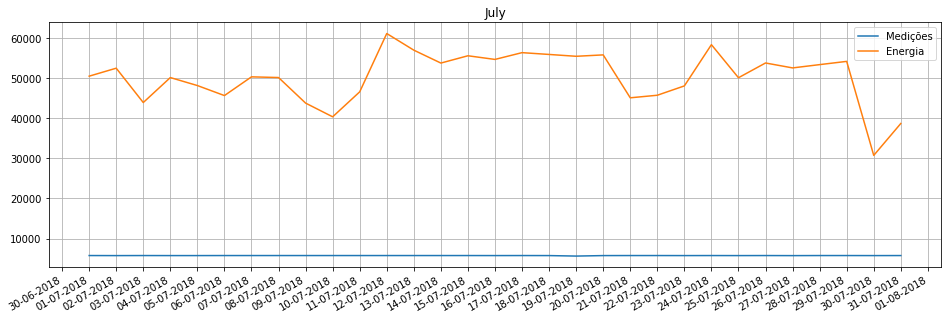

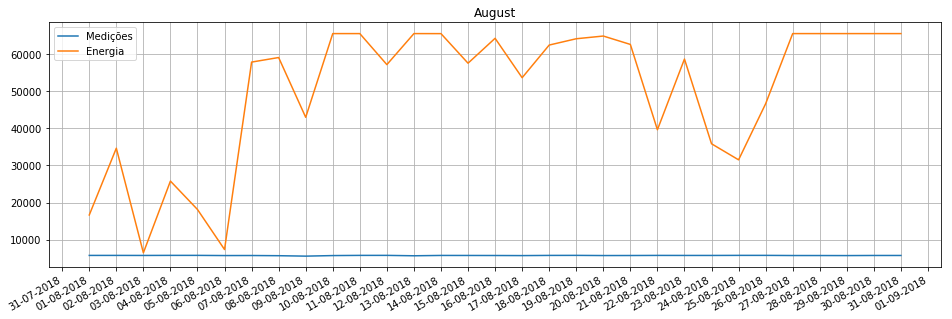

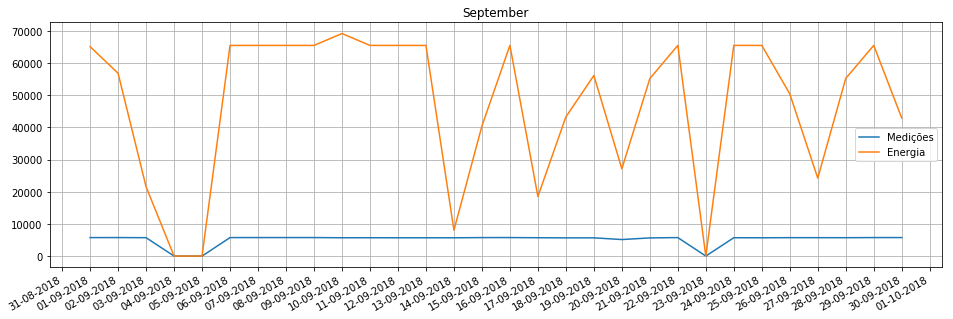

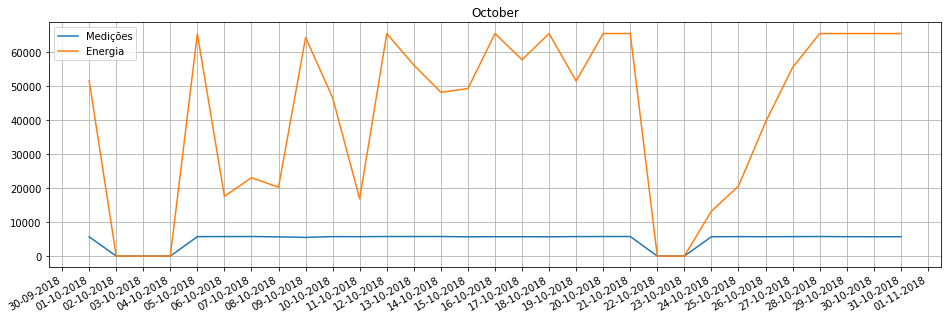

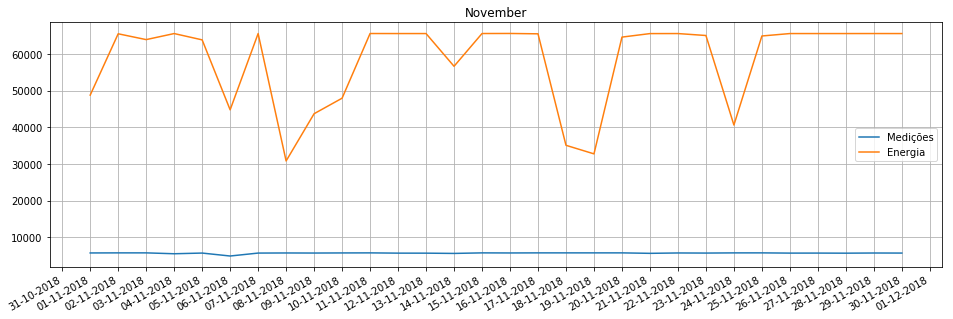

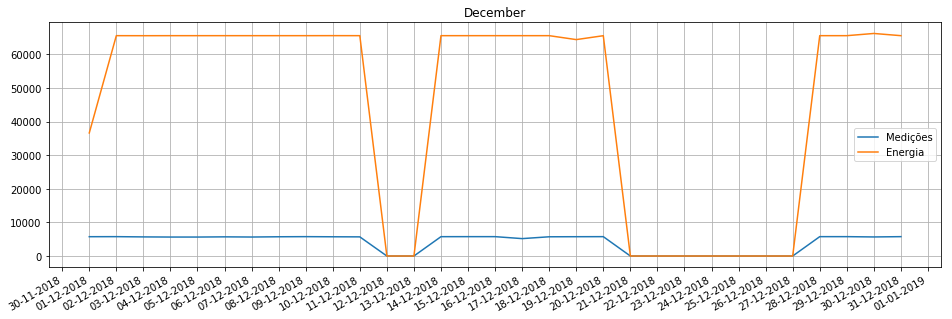

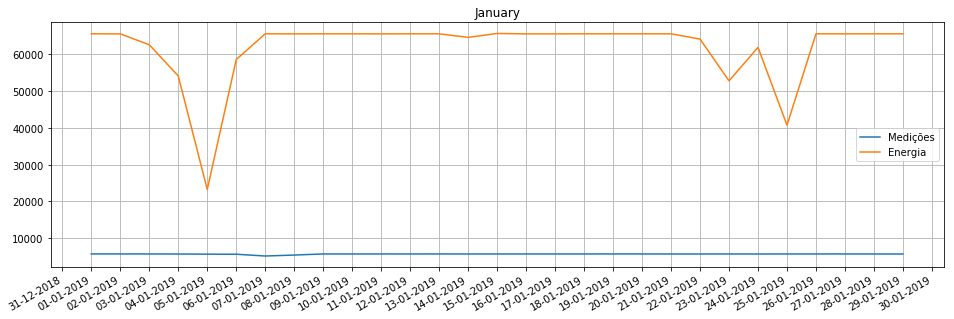

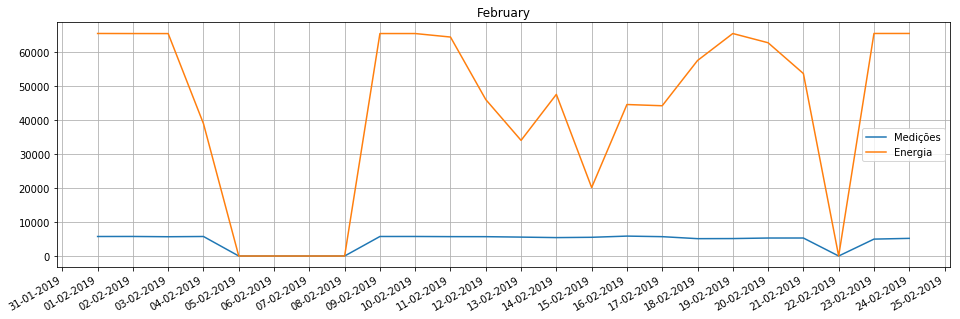

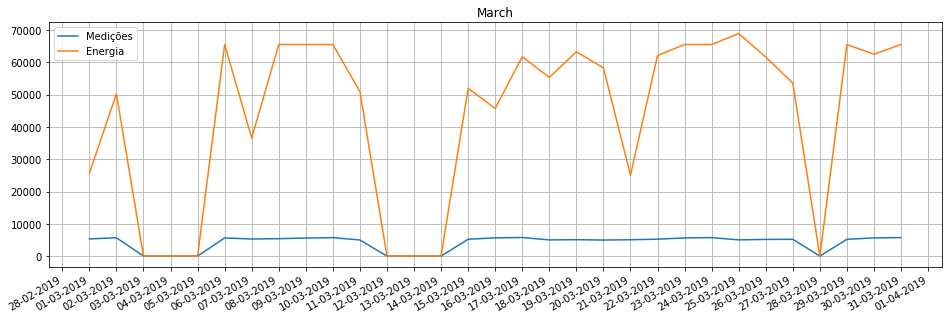

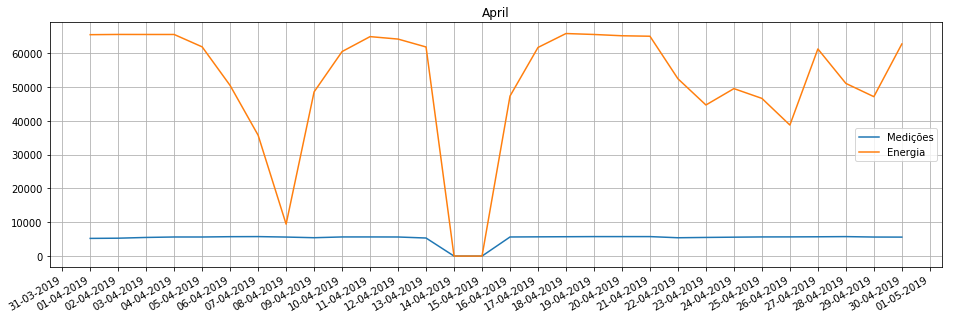

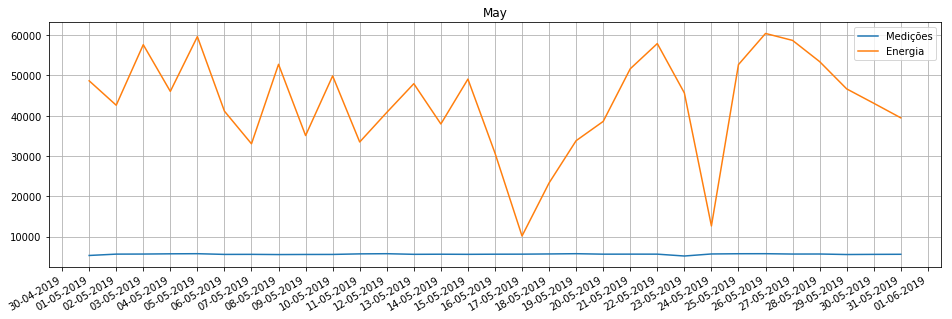

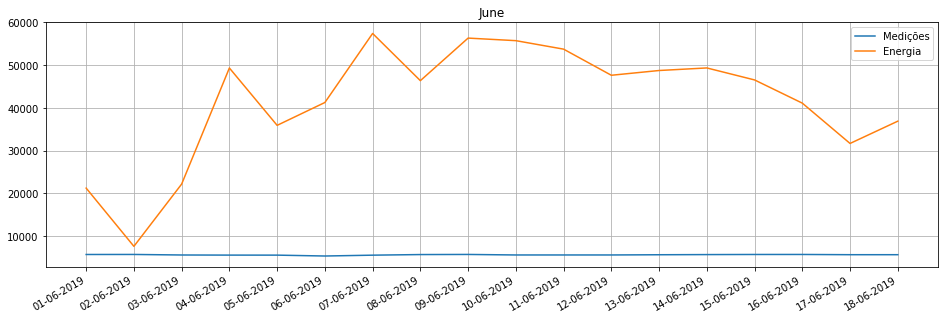

In [22]:
#CÉLULA TCC-21
for m in dfRawFoto1.groupby(by=[dfRawFoto1.index.month], sort=False):
    plt.figure(figsize=(16,5))
    plt.grid()
    #plt.plot(m[1].groupby(by=[m[1].index.date]).agg({"painel":'size',"energia":'sum'}))
    plt.plot(m[1].resample('D').agg({"painel":'size',"energia":'sum'}))#exibi datas excluidas
    plt.title(m[1].index.month_name()[0])
    #plt.gca().legend(m[1].columns)
    plt.gca().legend(["Medições","Energia"])
    plt.gca().xaxis.set_major_locator(DayLocator())#DayLocator(interval=5)
    plt.gca().xaxis.set_major_formatter(DateFormatter('%d-%m-%Y'))
    plt.gcf().autofmt_xdate()
    plt.show()

In [23]:
#CÉLULA TCC-21
day = dfRawFoto1.reset_index()[(dfRawFoto1.reset_index()['data'] >= '2019-06-09 00:00:00') & (dfRawFoto1.reset_index()['data'] <= '2019-06-09 23:59:59')]
day.set_index('data',inplace=True)
day.drop({'painel'},axis=1, inplace=True)

In [24]:
day.energia.sum()

56280.0

In [25]:
import plotly.graph_objs as go
from plotly.offline import init_notebook_mode, iplot
init_notebook_mode(connected=True)

In [26]:
trace1 = day.groupby(by=[day.index.hour]).energia.sum().reset_index()

In [27]:
trace = go.Bar(x=trace1['data'],y=trace1['energia'])
data = [trace]
layout = go.Layout(
    title='Energia acumulada por hora',titlefont=dict(size=25),
    xaxis=dict(title='Hora',
                titlefont=dict(size=20),
                ticks='outside',
                tick0=0,
                dtick=1,
                ticklen=5,
                tickwidth=1,
              ),
    yaxis=dict(title='Energia (wh)',titlefont=dict(size=20)))
iplot(go.Figure(data = [trace], layout=layout))

## 1.2 - Análise do dataset meteorológico

In [28]:
#CÉLULA TCC-0
dataSetMeteorologico = ['Meteorologico_Abr_2019.csv',
'Meteorologico_Ago_2018.csv',
'Meteorologico_Dez_2018.csv',
'Meteorologico_Fev_2019.csv',
'Meteorologico_Jan_2019.csv',
'Meteorologico_Jul_2018.csv',
'Meteorologico_Jun_2019.csv',
'Meteorologico_Mai_2019.csv',
'Meteorologico_Mar_2019.csv',
'Meteorologico_Nov_2018.csv',
'Meteorologico_Out_2018.csv',
'Meteorologico_Sep_2018.csv']

In [29]:
#CÉLULA TCC-0
for idx, data in  enumerate(dataSetMeteorologico):
    path = 'F:\Documentos\Data_Science\TCC\Projeto_final\{}'.format(data)
    if idx == 0:
        dfRawMete = loadDataFile(path, True)
    else:
        dfRawMete = pd.concat([dfRawMete, loadDataFile(path, True)])
dfRawMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 50502 entries, 2019-04-01 00:00:06 to 2018-09-01 00:00:06
Data columns (total 14 columns):
deficit_vapor_vmin         50502 non-null float64
deficit_vapor_vmedio       50502 non-null float64
ponto_orvalho_vmin         50502 non-null float64
ponto_orvalho_vmedio       50502 non-null float64
precipitacao_valor         50502 non-null float64
radiacao_solar_valor       50497 non-null float64
temperatura_ar_vmin        50502 non-null float64
temperatura_ar_vmedio      50502 non-null float64
temperatura_ar_vmax        50502 non-null float64
umidade_ar_vmin            50502 non-null float64
umidade_ar_vmedio          50502 non-null float64
umidade_ar_vmax            50502 non-null float64
velocidade_vento_vmedio    50502 non-null float64
velocidade_vento_vmax      50502 non-null float64
dtypes: float64(14)
memory usage: 5.8 MB


In [30]:
#CÉLULA TCC-
#Selecionando campos
dfRawMete.drop({
    'deficit_vapor_vmin',
    #'deficit_vapor_vmedio',
    'ponto_orvalho_vmin',
    #'ponto_orvalho_vmedio',
    #'precipitacao_valor',
    #'radiacao_solar_valor',
    'temperatura_ar_vmin',#
    #'temperatura_ar_vmedio',
    'temperatura_ar_vmax',#
    'umidade_ar_vmin',#
    #'umidade_ar_vmedio',
    'umidade_ar_vmax',#
    'velocidade_vento_vmedio',
    'velocidade_vento_vmax'
    },axis=1, inplace=True)

In [31]:
#CÉLULA TCC-
#Removendo campos vazios
dfRawMete.dropna(inplace=True)

In [32]:
#CÉLULA TCC-
dfRawMete.head()

,deficit_vapor_vmedio,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio
data,,,,,,
2019-04-01 00:00:06,0.56,17.0,0.0,0.0,21.20,77.26
2019-04-01 00:10:07,0.57,17.1,0.0,0.0,21.25,77.35
2019-04-01 00:20:06,0.58,17.1,0.0,0.0,21.29,77.05
2019-04-01 00:30:06,0.59,17.0,0.0,0.0,21.34,76.45
2019-04-01 00:40:07,0.60,16.9,0.0,0.0,21.37,76.05


In [33]:
dfRawMete.index.hour

Int64Index([0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
            ...
            1, 1, 1, 1, 1, 0, 0, 0, 0, 0],
           dtype='int64', name='data', length=50497)

In [36]:
#CÉLULA TCC-
qtdByDayMete = Counter(dfRawMete.index.date.astype('M8[D]'))
qtdByDayMete

Counter({numpy.datetime64('2019-04-01'): 144,
         numpy.datetime64('2019-04-02'): 144,
         numpy.datetime64('2019-04-03'): 144,
         numpy.datetime64('2019-04-04'): 144,
         numpy.datetime64('2019-04-05'): 140,
         numpy.datetime64('2019-04-06'): 144,
         numpy.datetime64('2019-04-07'): 141,
         numpy.datetime64('2019-04-08'): 144,
         numpy.datetime64('2019-04-09'): 142,
         numpy.datetime64('2019-04-10'): 139,
         numpy.datetime64('2019-04-11'): 144,
         numpy.datetime64('2019-04-12'): 144,
         numpy.datetime64('2019-04-13'): 141,
         numpy.datetime64('2019-04-14'): 143,
         numpy.datetime64('2019-04-15'): 144,
         numpy.datetime64('2019-04-16'): 141,
         numpy.datetime64('2019-04-17'): 144,
         numpy.datetime64('2019-04-18'): 143,
         numpy.datetime64('2019-04-19'): 137,
         numpy.datetime64('2019-04-20'): 143,
         numpy.datetime64('2019-04-21'): 143,
         numpy.datetime64('2019-04

In [37]:
#CÉLULA TCC- Aplicando um teto para descarte de dias com falhas em medições
lstDaysOutMete = []
for i in list(dict.fromkeys(qtdByDayMete.elements())): 
    if qtdByDayMete[i] < 144 * court : # 144 - 10 em 10 minutos, todal de 144 medições por dia
        lstDaysOutMete.append(i.astype(datetime))
lstDaysOutMete

[datetime.date(2018, 8, 19),
 datetime.date(2018, 12, 1),
 datetime.date(2018, 12, 2),
 datetime.date(2018, 12, 3),
 datetime.date(2018, 12, 4),
 datetime.date(2018, 12, 5),
 datetime.date(2018, 12, 6),
 datetime.date(2018, 12, 7),
 datetime.date(2018, 12, 8),
 datetime.date(2018, 12, 10),
 datetime.date(2018, 12, 11),
 datetime.date(2018, 12, 13),
 datetime.date(2018, 12, 14),
 datetime.date(2018, 12, 15),
 datetime.date(2018, 12, 16),
 datetime.date(2018, 12, 17),
 datetime.date(2019, 2, 11),
 datetime.date(2019, 6, 25),
 datetime.date(2018, 10, 22),
 datetime.date(2018, 10, 23)]

In [38]:
#CÉLULA TCC- Removendo dias com medições abaixo do teto
dfRawMete['date'] = dfRawMete.index.date # coluna auxiliar
for i in lstDaysOutMete:# correndo todos os dias com falhas nas medições
    idx = dfRawMete[dfRawMete.date == i].index # obtendo o index
    dfRawMete.drop(idx, inplace=True) # removendo do dataset
dfRawMete.drop(['date'], axis=1, inplace=True) # removendo coluna auxiliar

In [39]:
dfRawMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 48505 entries, 2019-04-01 00:00:06 to 2018-09-01 00:00:06
Data columns (total 6 columns):
deficit_vapor_vmedio     48505 non-null float64
ponto_orvalho_vmedio     48505 non-null float64
precipitacao_valor       48505 non-null float64
radiacao_solar_valor     48505 non-null float64
temperatura_ar_vmedio    48505 non-null float64
umidade_ar_vmedio        48505 non-null float64
dtypes: float64(6)
memory usage: 2.6 MB


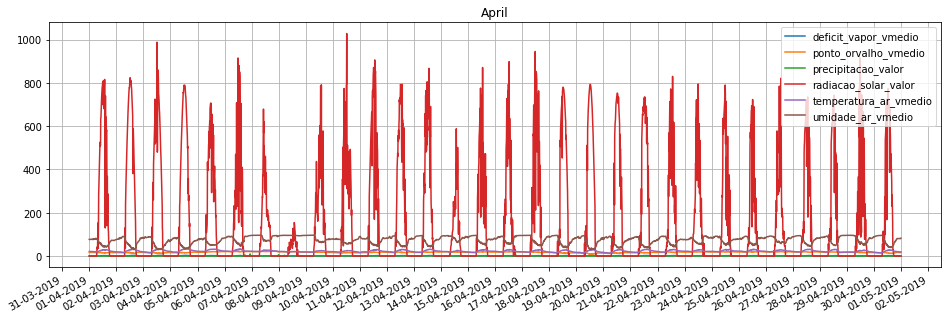

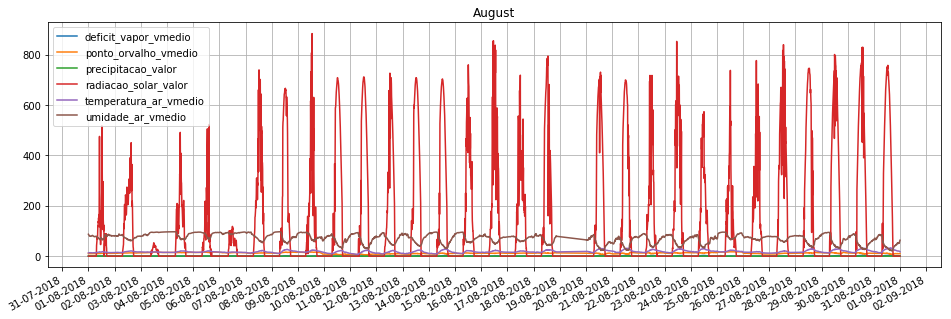

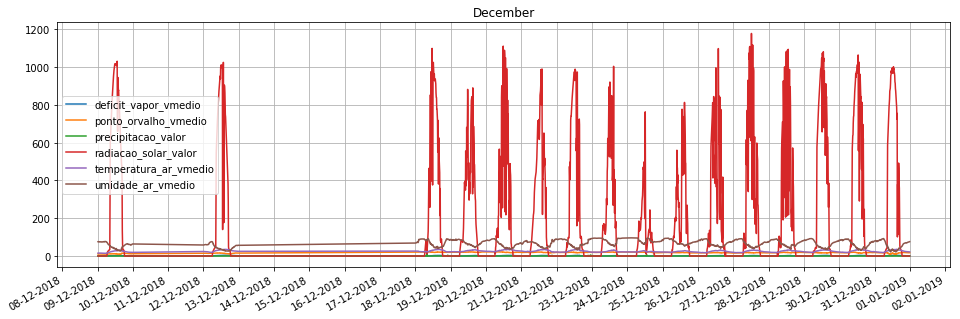

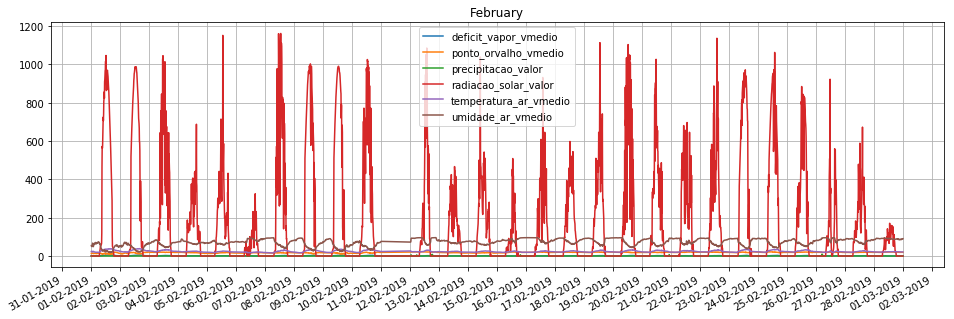

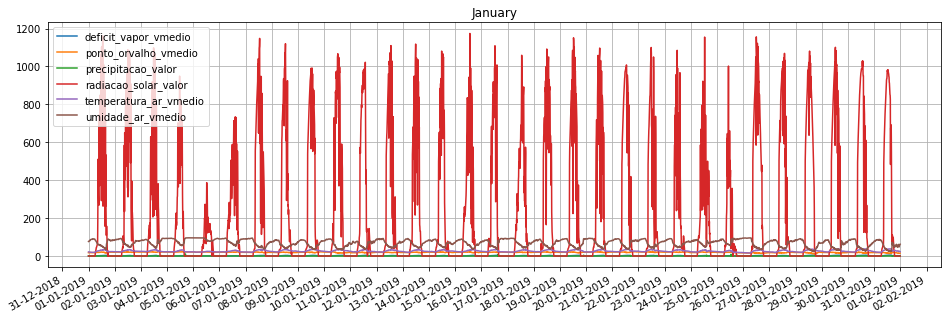

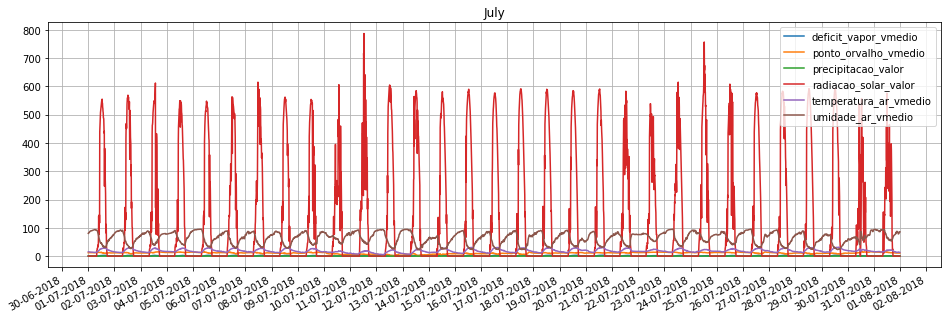

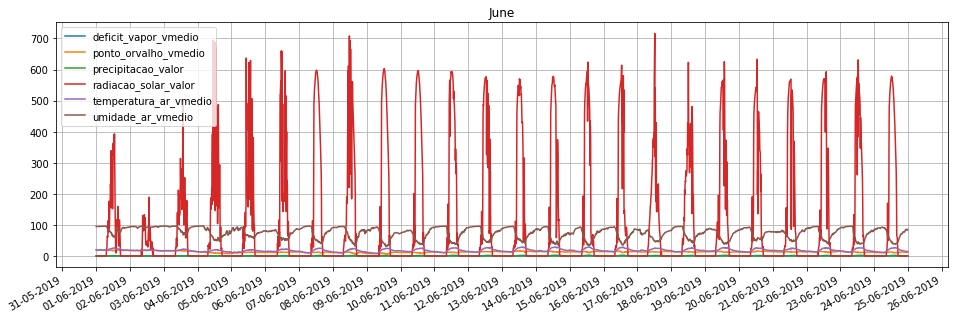

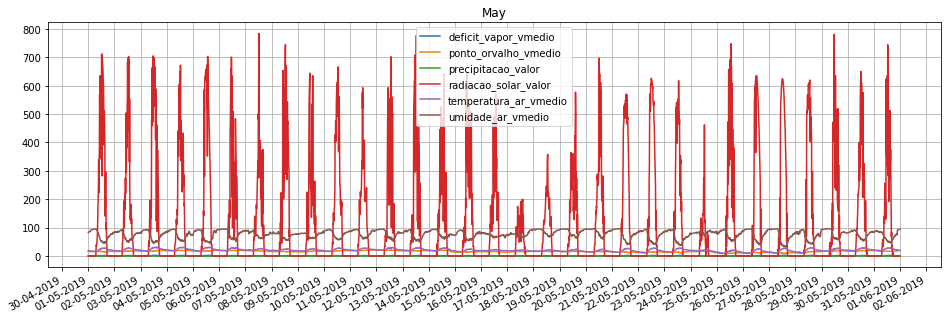

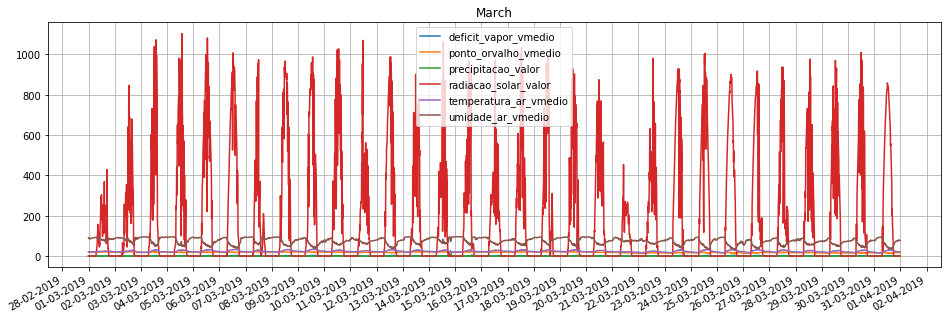

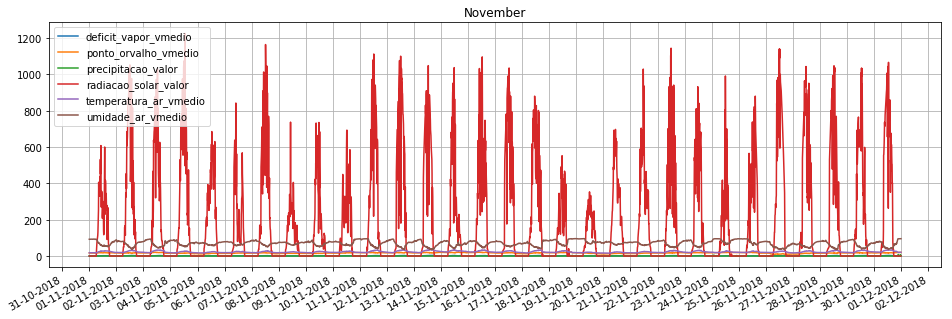

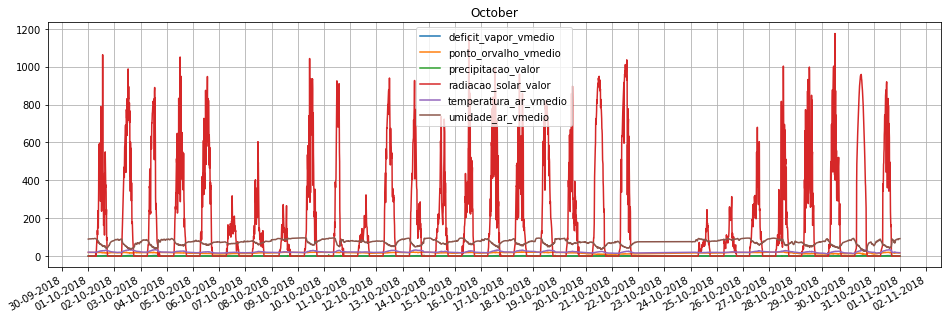

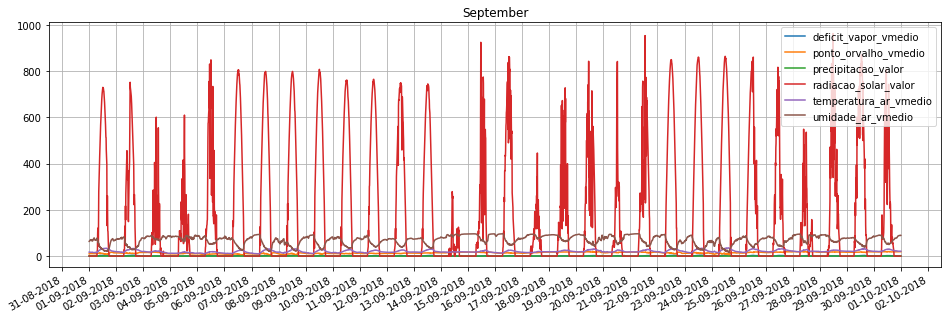

In [43]:
#CÉLULA TCC-
#showDataPlot(dfRawMete)
for m in dfRawMete.groupby(by=[dfRawMete.index.month], sort=False):
    plt.figure(figsize=(16,5))
    plt.grid()
    plt.plot(m[1])
    #plt.plot(m[1].groupby(by=[m[1].index.date]).agg({"painel":'size',"energia":'sum'}))
    plt.title(m[1].index.month_name()[0])
    plt.gca().legend(m[1].columns)
    plt.gca().xaxis.set_major_locator(DayLocator())#DayLocator(interval=5)
    plt.gca().xaxis.set_major_formatter(DateFormatter('%d-%m-%Y'))
    plt.gcf().autofmt_xdate()
    plt.show()

## 1.3 - Unificando os datasets

Como os datasets apresentam medições distintas em tempos e frequência diferentes, como demonstra a representação abaixo:
* Fotovoltaico - apresenta em média 1 medição a cada 15 a 20 segundos, totalizando em média 240 medições por hora;
* Meteorologico - apresenta em média 1 mediação a cada 10 minutos, totalizando em média 6 medições por hora;

Será utilizado a tecnica de UpSample para os dados fotovoltaicos afim de centralizar as medições em um tempo maior, e para os dados meteorológicos a tecnica de DownSample para ajustar as medições em períodos faltantes, visando também um mesmo padrão de tempo nos dois datasets.

In [44]:
#CÉLULA TCC-
#D         calendar day frequency
#H         hourly frequency
#T, min    minutely frequency
freq = '10T' #1D - 1 dia,  10T - 10 min , 60T - 1 h   ou ('60min', on='TIME')

## 1.3.1 - DownSample

In [45]:
dfRawFoto1.head()

,painel,energia
data,,
2018-07-01 00:00:06.897,1.0,0.0
2018-07-01 00:00:10.697,1.0,0.0
2018-07-01 00:00:28.477,1.0,0.0
2018-07-01 00:00:48.993,1.0,0.0
2018-07-01 00:01:07.387,1.0,0.0


In [46]:
#CÉLULA TCC-
downFoto = dfRawFoto1.resample(freq) #de 10 em 10 minutos cravados
newDownFoto = downFoto.agg({
    "painel":'max',
    #"potencia":'mean',
    "energia":'sum'
})
interDownFoto = newDownFoto.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
print(interDownFoto.head())

                     painel  energia
data                                
2018-07-01 00:00:00     1.0      0.0
2018-07-01 00:10:00     1.0      0.0
2018-07-01 00:20:00     1.0      0.0
2018-07-01 00:30:00     1.0      0.0
2018-07-01 00:40:00     1.0      0.0


In [47]:
interDownFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 50832 entries, 2018-07-01 00:00:00 to 2019-06-18 23:50:00
Freq: 10T
Data columns (total 2 columns):
painel     50832 non-null float64
energia    50832 non-null float64
dtypes: float64(2)
memory usage: 3.7 MB


In [48]:
#CÉLULA TCC- Removendo novamente, pois o resample gera os dias, dias com medições abaixo do teto
interDownFoto['date'] = interDownFoto.index.date # coluna auxiliar
for i in lstDaysOut:# correndo todos os dias com falhas nas medições
    idx = interDownFoto[interDownFoto.date == i].index # obtendo o index
    interDownFoto.drop(idx, inplace=True) # removendo do dataset
interDownFoto.drop(['date'], axis=1, inplace=True) # removendo coluna auxiliar

In [49]:
interDownFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 46656 entries, 2018-07-01 00:00:00 to 2019-06-18 23:50:00
Data columns (total 2 columns):
painel     46656 non-null float64
energia    46656 non-null float64
dtypes: float64(2)
memory usage: 1.1 MB


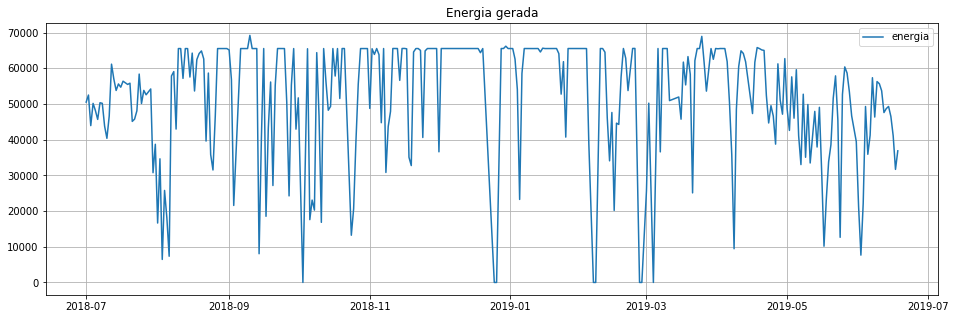

In [50]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
plt.title("Energia gerada")
showDataPlot(interDownFoto.groupby(by=interDownFoto.index.date).agg({"energia":'sum'}))
##Dividir gráficos

## 1.3.2 - UpSample

In [51]:
#CÉLULA TCC-
downMete = dfRawMete.resample(freq) #de 10 em 10 minutos cravados
newDownMete = downMete.agg({
    #'deficit_vapor_vmin':'min',
    'deficit_vapor_vmedio':'mean',
    #'ponto_orvalho_vmin':'min',
    'ponto_orvalho_vmedio':'mean',
    'precipitacao_valor':'mean',
    'radiacao_solar_valor':'mean',
    #'temperatura_ar_vmin':'min',
    'temperatura_ar_vmedio':'mean',
    #'temperatura_ar_vmax':'max',
    #'umidade_ar_vmin':'min',
    'umidade_ar_vmedio':'mean',
    #'umidade_ar_vmax':'max',
    #'velocidade_vento_vmedio':'mean',
    #'velocidade_vento_vmax':'max'
})
interDownMete = newDownMete.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
interDownMete.head()

,deficit_vapor_vmedio,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio
data,,,,,,
2018-07-01 00:00:00,0.33,11.7,0.0,0.0,15.18,80.27
2018-07-01 00:10:00,0.31,12.0,0.0,0.0,15.21,81.63
2018-07-01 00:20:00,0.32,12.0,0.0,0.0,15.18,81.43
2018-07-01 00:30:00,0.31,11.9,0.0,0.0,15.05,81.70
2018-07-01 00:40:00,0.29,11.9,0.0,0.0,14.90,82.62


In [52]:
#CÉLULA TCC
interDownMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 51696 entries, 2018-07-01 00:00:00 to 2019-06-24 23:50:00
Freq: 10T
Data columns (total 6 columns):
deficit_vapor_vmedio     51696 non-null float64
ponto_orvalho_vmedio     51696 non-null float64
precipitacao_valor       51696 non-null float64
radiacao_solar_valor     51696 non-null float64
temperatura_ar_vmedio    51696 non-null float64
umidade_ar_vmedio        51696 non-null float64
dtypes: float64(6)
memory usage: 5.3 MB


In [53]:
#CÉLULA TCC- Removendo dias com medições abaixo do teto
interDownMete['date'] = interDownMete.index.date # coluna auxiliar
for i in lstDaysOutMete:# correndo todos os dias com falhas nas medições
    idx = interDownMete[interDownMete.date == i].index # obtendo o index
    interDownMete.drop(idx, inplace=True) # removendo do dataset
interDownMete.drop(['date'], axis=1, inplace=True) # removendo coluna auxiliar

In [54]:
#CÉLULA TCC
interDownMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 48960 entries, 2018-07-01 00:00:00 to 2019-06-24 23:50:00
Data columns (total 6 columns):
deficit_vapor_vmedio     48960 non-null float64
ponto_orvalho_vmedio     48960 non-null float64
precipitacao_valor       48960 non-null float64
radiacao_solar_valor     48960 non-null float64
temperatura_ar_vmedio    48960 non-null float64
umidade_ar_vmedio        48960 non-null float64
dtypes: float64(6)
memory usage: 2.6 MB


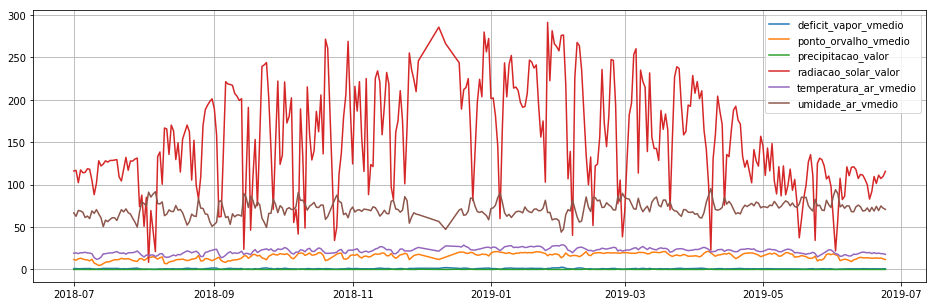

In [55]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
#showDataPlot(interDownMete)
plt.title("")
showDataPlot(interDownMete.groupby(by=interDownMete.index.date).agg({
    #'deficit_vapor_vmin':'min',
    'deficit_vapor_vmedio':'mean',
    #'ponto_orvalho_vmin':'min',
    'ponto_orvalho_vmedio':'mean',
    'precipitacao_valor':'mean',
    'radiacao_solar_valor':'mean',
    #'temperatura_ar_vmin':'min',
    'temperatura_ar_vmedio':'mean',
    #'temperatura_ar_vmax':'max',
    #'umidade_ar_vmin':'min',
    'umidade_ar_vmedio':'mean',
    #'umidade_ar_vmax':'max',
    #'velocidade_vento_vmedio':'mean',
    #'velocidade_vento_vmax':'max'
}))
##Dividir gráficos 

## 1.3.3 - Realizando o merge

Com os datasets padronizados na mesma freqência de medições, é possível realizar juntar ('merge') os dois em um só dataset, tornando o dataset mais interesssante por conter ambos os registros unificados. 

In [56]:
#CÉLULA TCC-
dfSet1 = pd.merge(interDownFoto, interDownMete, left_index=True, right_index=True)
#dfSet1['TotalSegundos'] = dfSet1.index.hour * 360 + dfSet1.index.minute * 60 + dfSet1.index.second
dfSet1.reset_index(inplace=True)

In [57]:
#CÉLULA TCC-
dfSet1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44352 entries, 0 to 44351
Data columns (total 9 columns):
data                     44352 non-null datetime64[ns]
painel                   44352 non-null float64
energia                  44352 non-null float64
deficit_vapor_vmedio     44352 non-null float64
ponto_orvalho_vmedio     44352 non-null float64
precipitacao_valor       44352 non-null float64
radiacao_solar_valor     44352 non-null float64
temperatura_ar_vmedio    44352 non-null float64
umidade_ar_vmedio        44352 non-null float64
dtypes: datetime64[ns](1), float64(8)
memory usage: 3.0 MB


In [58]:
#CÉLULA TCC-
saveDataFile(dfSet1,'FotoMet_P1_DataSets_10T.csv')
#saveDataFile(dfSet1,'input/FotoMet_P1_Sep_2018.csv')

In [59]:
#CÉLULA TCC-
dfSet1 = loadDataFile('FotoMet_P1_DataSets_10T.csv', False)
#dfSet1 = loadDataFile('input/FotoMet_P1_Sep_2018.csv', False)

In [60]:
#CÉLULA TCC-
dfSet1.describe()

,painel,energia,deficit_vapor_vmedio,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio
count,44352.0,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000
mean,1.0,356.009673,0.884567,15.656145,0.027618,152.527676,21.759233,71.353613
std,0.0,604.254185,0.798869,3.733724,0.284130,252.653467,5.180582,17.505951
min,1.0,0.000000,0.040000,0.500000,0.000000,0.000000,5.140000,15.560000
25%,1.0,0.000000,0.300000,12.800000,0.000000,0.000000,18.350000,59.540000
50%,1.0,0.000000,0.590000,16.300000,0.000000,0.000000,21.310000,74.650000
75%,1.0,576.000000,1.250000,18.700000,0.000000,218.000000,25.140000,85.380000
max,1.0,9297.000000,5.440000,24.600000,11.800000,1225.000000,38.820000,96.800000


In [61]:
dfSet1.head()

,data,painel,energia,deficit_vapor_vmedio,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio
0,2018-07-01 00:00:00,1.0,0.0,0.33,11.7,0.0,0.0,15.18,80.27
1,2018-07-01 00:10:00,1.0,0.0,0.31,12.0,0.0,0.0,15.21,81.63
2,2018-07-01 00:20:00,1.0,0.0,0.32,12.0,0.0,0.0,15.18,81.43
3,2018-07-01 00:30:00,1.0,0.0,0.31,11.9,0.0,0.0,15.05,81.70
4,2018-07-01 00:40:00,1.0,0.0,0.29,11.9,0.0,0.0,14.90,82.62


## 2 - Normalização

Descrição ...

In [62]:
#CÉLULA TCC-
df = dfSet1.drop(['data'],axis=1)

In [63]:
#CÉLULA TCC-
from sklearn.preprocessing import MinMaxScaler
min_max_scaler = MinMaxScaler()
df[df.columns] = min_max_scaler.fit_transform(df[df.columns])
df.describe()

,painel,energia,deficit_vapor_vmedio,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio
count,44352.0,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000
mean,0.0,0.038293,0.156401,0.628886,0.002340,0.124512,0.493445,0.686775
std,0.0,0.064995,0.147939,0.154926,0.024079,0.206248,0.153818,0.215484
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,0.048148,0.510373,0.000000,0.000000,0.392221,0.541359
50%,0.0,0.000000,0.101852,0.655602,0.000000,0.000000,0.480107,0.727351
75%,0.0,0.061955,0.224074,0.755187,0.000000,0.177959,0.593824,0.859429
max,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [64]:
#from sklearn.preprocessing import StandardScaler
#scaler = StandardScaler()
#df[df.columns] = scaler.fit_transform(df[df.columns])
#df.describe()

## 3 - Treinamento do modelo

Descrição ...

In [65]:
#CÉLULA TCC-
import seaborn as sns

from sklearn import model_selection
from sklearn import linear_model
from sklearn.ensemble import RandomForestRegressor

from sklearn import metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [66]:
#CÉLULA TCC-
def showPairPlot(dataFrame):

    pairPlot = sns.pairplot(
        dataFrame,
        size=2.0,
        aspect=1.4,
        plot_kws=dict(edgecolor="k", linewidth=0.2),
        diag_kws=dict(shade=True),        
        diag_kind="kde",
    )               
                 
    fig = pairPlot.fig
    fig.subplots_adjust(top=0.95)
    fig.suptitle(
        'Análise de parâmetros', 
        fontsize=13, 
        fontweight='bold'
    )

In [67]:
#CÉLULA TCC-
def showHeatMap(dataFrame):
    
    fig, (ax) = plt.subplots(1, 1, figsize=(11,7))
    heatMap = sns.heatmap(
        dataFrame.corr(), 
        ax=ax,           
        cmap="coolwarm",
        annot=True, 
        fmt='.2f',
        linewidths=.07
    )

    fig.suptitle(
        'Correlação de parâmetros', 
        fontsize=13, 
        fontweight='bold'
    )

In [68]:
#CÉLULA TCC-
def showResultPlot(y_pred,y_test):
    plt.figure(figsize=(17,7))
    y_pred = y_pred.T

    plt.plot(range(len(y_pred)), y_pred, 'ro-')
    plt.plot(range(len(y_test)), y_test, 'b+-')
    plt.gca().legend(('Previsão','Real'))
    #plt.xticks(range(0,1150,50))
    plt.grid()
    plt.show()

In [69]:
#CÉLULA TCC-
def showResult(model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)
    y_pred_Train = model.predict(X_train)
    y_pred_Test = model.predict(X_test)

    #print(model)# exibição dos parametros utilizados no modelo
    print('------------------- TREINO -------------------------')
    print('MSE: {:.6f}'.format(metrics.mean_squared_error(y_train, y_pred_Train)))
    print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(y_train, y_pred_Train))))
    #print('r²: {:.2f} %'.format(model.score(X_train, y_train) * 100))
    print('r²: {:.2f} %'.format(r2_score(y_train, y_pred_Train) * 100))
    print('MAE: {:.6f}'.format(mean_absolute_error(y_train, y_pred_Train)))
    print('------------------- TESTE ---------------------------')
    print('MSE: {:.6f}'.format(metrics.mean_squared_error(y_test, y_pred_Test)))
    print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(y_test, y_pred_Test))))
    #print('r²: {:.2f} %'.format(model.score(X_test, y_test) * 100))
    print('r²: {:.2f} %'.format(r2_score(y_test, y_pred_Test) * 100))
    print('MAE: {:.6f}'.format(mean_absolute_error(y_test, y_pred_Test)))

    print('----------------------------------------------------')
    showResultPlot(y_pred_Test,y_test)
    return model

In [70]:
#CÉLULA TCC-
dfParameters = df.drop([
    'painel',
    #'potencia',#
    #'energia',#
    #'deficit_vapor_vmin',#
    #'deficit_vapor_vmedio',#
    #'ponto_orvalho_vmin',
    #'ponto_orvalho_vmedio',
    #'precipitacao_valor',
    #'radiacao_solar_valor',
    #'temperatura_ar_vmin',#
    #'temperatura_ar_vmedio',
    #'temperatura_ar_vmax',#
    #'umidade_ar_vmin',#
    #'umidade_ar_vmedio',
    #'umidade_ar_vmax',#
    #'velocidade_vento_vmedio',
    #'velocidade_vento_vmax'
    ],axis=1)

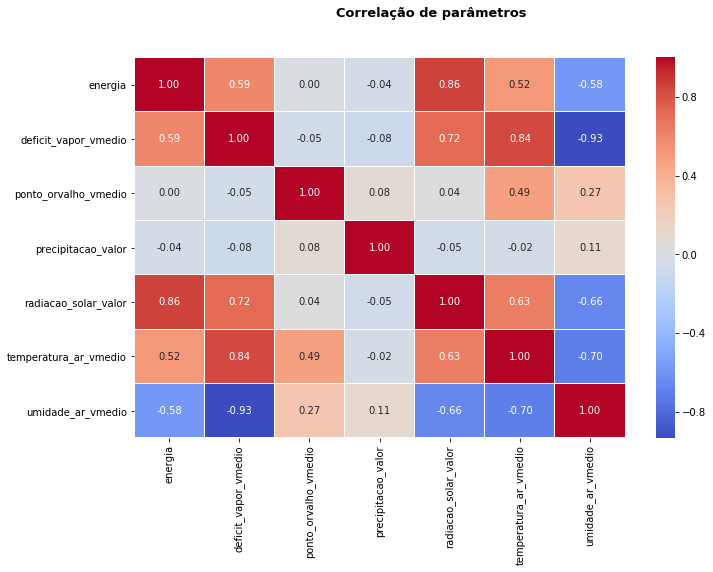

In [71]:
#CÉLULA TCC-
showHeatMap(dfParameters)

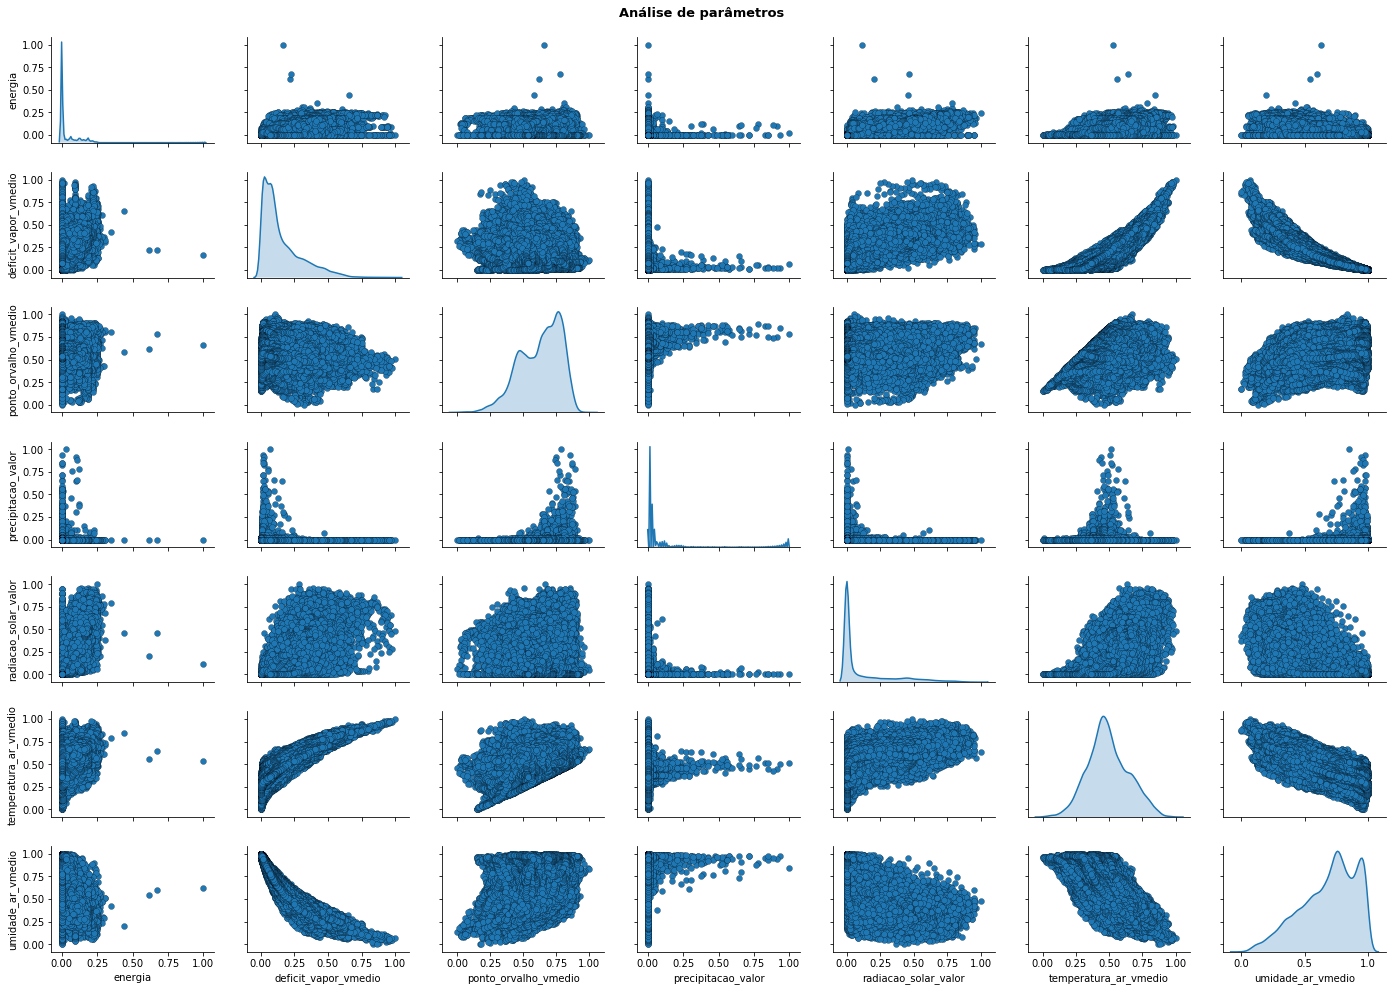

In [72]:
#CÉLULA TCC-
showPairPlot(dfParameters)

In [73]:
#CÉLULA TCC-
X = dfParameters.drop(['energia'],axis=1)
y = dfParameters.energia

In [74]:
#CÉLULA TCC-
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.25, random_state=42)

In [75]:
#CÉLULA TCC-
print(X_train.shape)
print(y_train.shape)

(33264, 6)
(33264,)


In [76]:
#CÉLULA TCC-
print(X_test.shape)
print(y_test.shape)

(11088, 6)
(11088,)


Regressão  Linear

https://towardsdatascience.com/linear-regression-in-python-9a1f5f000606

https://www.dataquest.io/blog/understanding-regression-error-metrics/

https://realpython.com/linear-regression-in-python/

https://www.analyticsvidhya.com/blog/2017/06/a-comprehensive-guide-for-linear-ridge-and-lasso-regression/

https://jovianlin.io/data-visualization-seaborn-part-2/

----------------------------------------------------
----------      REGRESSÃO LINEAR       -------------
----------------------------------------------------
------------------- TREINO -------------------------
MSE: 0.001017
RMSE: 0.031885
r²: 75.96 %
MAE: 0.017699
------------------- TESTE ---------------------------
MSE: 0.001049
RMSE: 0.032383
r²: 75.08 %
MAE: 0.017812
----------------------------------------------------


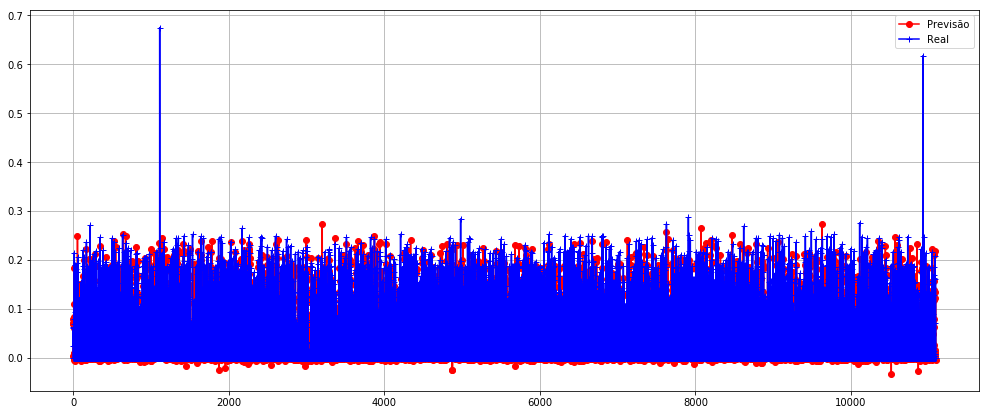

                       0  Coeficiente estimado
3   radiacao_solar_valor              0.285927
2     precipitacao_valor              0.032407
4  temperatura_ar_vmedio              0.016645
1   ponto_orvalho_vmedio              0.005904
5      umidade_ar_vmedio             -0.094011
0   deficit_vapor_vmedio             -0.167731


In [77]:
#CÉLULA TCC-
LinearRegression = linear_model.LinearRegression()

print('----------------------------------------------------')
print('----------      REGRESSÃO LINEAR       -------------')
print('----------------------------------------------------')
modelLinearRegression = showResult(LinearRegression, X_train, y_train, X_test, y_test)
#print(model.intercept_)
coeff = pd.DataFrame(X_train.columns)
coeff['Coeficiente estimado'] = pd.Series(modelLinearRegression.coef_)
coeff.sort_values(by='Coeficiente estimado', inplace=True, ascending=False)
print(coeff)
#print(modelRegLinear.coef_)
#for idx, col_name in enumerate(X_train.columns):
#    print("Ccoeficiente para a coluna '{}': {:.6f}".format(col_name, model.coef_[idx]))


Random Forest Regressor

----------------------------------------------------
------------      RANDOM FOREST     ----------------
----------------------------------------------------
------------------- TREINO -------------------------
MSE: 0.000122
RMSE: 0.011028
r²: 97.12 %
MAE: 0.005136
------------------- TESTE ---------------------------
MSE: 0.000944
RMSE: 0.030733
r²: 77.55 %
MAE: 0.014215
----------------------------------------------------


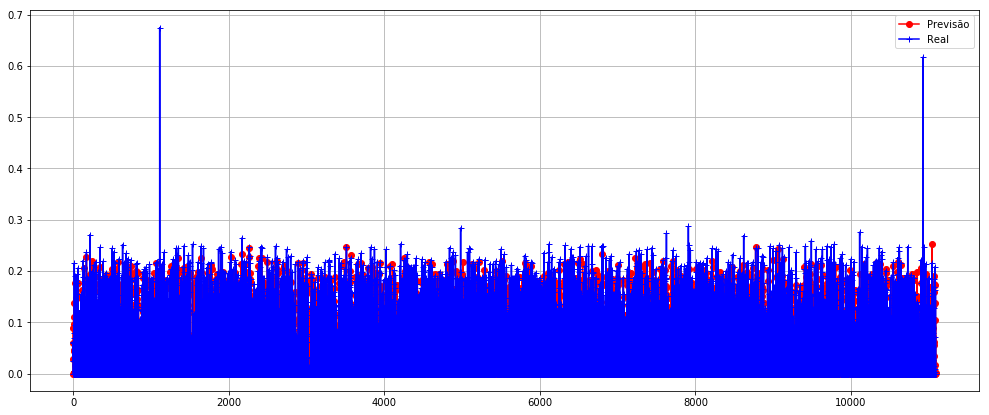

In [78]:
#CÉLULA TCC-
RandomForest = RandomForestRegressor(n_estimators=350, random_state=0)
    
print('----------------------------------------------------')
print('------------      RANDOM FOREST     ----------------')
print('----------------------------------------------------')

modelRandomForest = showResult(RandomForest, X_train, y_train, X_test, y_test)

In [79]:
#MAE é a média da diferença absoluta entre os valores previstos e o valor observado

#O numerador é MSE (média dos quadrados dos residuais) e o denominador é a variância nos valores Y. Quanto mais alto o MSE, menor o R_squared e mais pobre é o modelo.

#Por que você deve escolher R² Ajustado sobre R²?
#Existem alguns problemas com o R² normal que são resolvidos pelo R² Ajustado. Um R² ajustado considerará a melhoria marginal adicionada por um termo adicional em seu modelo. Por isso, aumentará se você adicionar os termos úteis e diminuirá se você adicionar preditores menos úteis. No entanto, o R² aumenta com termos crescentes, mesmo que o modelo não esteja realmente melhorando.

#O R², também chamado de Coeficiente de Determinação, diz o quanto meu modelo está prevendo corretamente.

#RMSE (Root Mean Square Error)(Erro Quadrado Médio da Raiz)
#Representa o desvio padrão da amostra das diferenças entre os valores previstos e os valores observados (chamados resíduos)

In [80]:
#Teste F de Significância global: afirma se ao menos uma variável do meu modelo está relacionada com a variável alvo. Para isso, o valor-p desta estatística precisa ser menor que 0.05

#Teste de Significância individuais ou p-values dos coeficientes: diz o quanto das variáveis preditoras explicam a variável alvo. A métrica padrão é o p-value ser menor que 0.05.

#Coeficiente R²: diz o quanto o meu modelo explica seus resultados. É um valor entre 0 e 1. Quanto mais próximo de 1, melhor.

## 4 - Otimização

## 5 - Resultados

# Rede LSTM

In [81]:
import numpy as np
import keras as K
import tensorflow as tf
import pandas as pd
import os
from matplotlib import pyplot as plt
import seaborn as sns
%matplotlib inline
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'

from sklearn.preprocessing import MinMaxScaler

In [82]:
np.random.seed(1)
tf.set_random_seed(1)

In [84]:
dfSet1 = loadDataFile('FotoMet_P1_DataSets_10T.csv', True)
dfSet1.head()

,painel,energia,deficit_vapor_vmedio,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio
data,,,,,,,,
2018-07-01 00:00:00,1.0,0.0,0.33,11.7,0.0,0.0,15.18,80.27
2018-07-01 00:10:00,1.0,0.0,0.31,12.0,0.0,0.0,15.21,81.63
2018-07-01 00:20:00,1.0,0.0,0.32,12.0,0.0,0.0,15.18,81.43
2018-07-01 00:30:00,1.0,0.0,0.31,11.9,0.0,0.0,15.05,81.70
2018-07-01 00:40:00,1.0,0.0,0.29,11.9,0.0,0.0,14.90,82.62


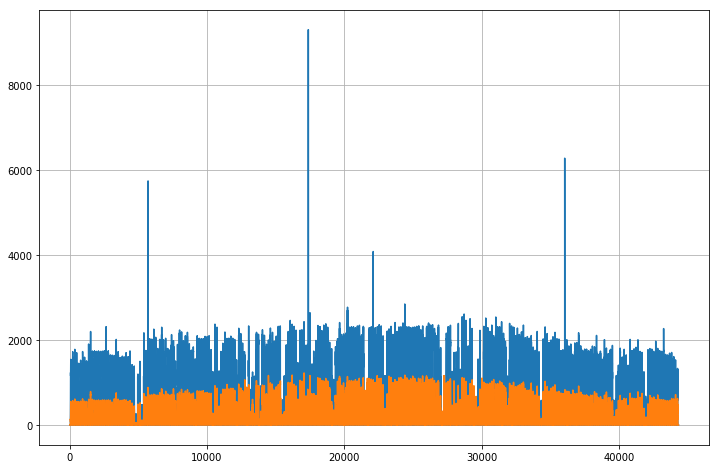

In [85]:
enerValues = np.array(dfSet1[["energia","radiacao_solar_valor"]][:])
enerValues = enerValues.reshape(enerValues.shape[0],2)

plt.figure(figsize=(12,8))
plt.plot(enerValues)
plt.grid()
plt.show()

In [86]:
scaler = MinMaxScaler(feature_range=(0,1))
scaler = scaler.fit(enerValues)
enerValuesScaled = scaler.transform(enerValues)

In [87]:
from sklearn.model_selection import train_test_split
time_steps = 1 * 24 * 6 # 6 medicoes por hora, totalizando 144 mediçoes por dia
prediction = 1 #valor a ser previsto (um dia a frente)
num_features = 2 # numero de atributos usados

In [88]:
enerValuesScaled.shape

(44352, 2)

In [89]:
(len(enerValuesScaled) - (len(enerValuesScaled) % time_steps))

44352

In [90]:
(len(enerValuesScaled) % time_steps)

0

In [91]:
X.shape

(44352, 6)

In [92]:
X = enerValuesScaled[0:(len(enerValuesScaled) - (len(enerValuesScaled) % time_steps))] #DADOS NORMALIZADOS
X_train = X.reshape(-1, time_steps, num_features) #Esta formatação é necessária para o LSTM 

#Valores de Saída: aqui a saída é composta por apenas 1 valor (1 label previsto após a exibição da sequencia de 1 dia)
y_train = X_train[1:, 0, 0]
y_train  = np.append(y_train, enerValuesScaled[len(enerValuesScaled) - time_steps + 1][0])#Primeira coluna campo principal "energia"
y_train = y_train.reshape(-1, 1)
print(y_train.shape)

#Conjunto de validação com os dados remanescentes do dataset
remain = len(enerValuesScaled) - len(X)#
X_aux = enerValuesScaled[ - remain - time_steps :]#

#o -1 é para não incluir a ultima linha porque nao sabemos o valor de saída neste caso
y_val = []
y_test_val = []
for start in range(len(X_aux) - time_steps + prediction - 1) : 
    row = X_aux[start:time_steps + start]
    y_val.append(row)
    y_test_val.append(X_aux[time_steps + start][0])#somente o campo de interesse

y_val = np.array(y_val)
y_test_val = np.array(y_test_val)

#AS variáveis X_train e y_train contém os dados uteis formatados conforme o subitem 1. Vamos dividir parte deste array para testes
X_train, X_test, y_train, y_test = train_test_split(X_train, y_train, test_size = 0.2, random_state = 0, shuffle=False)

(308, 1)


In [93]:
X_train.shape

(246, 144, 2)

In [94]:
X_test.shape

(62, 144, 2)

In [95]:
#CÉLULA KE-LIB-10
#Montando a rede recorrente 'LSTM-Dense'
RS_VALUE = False
batch_size = 1

#Limpa o modelo previamente usado, senão irá acumular camadas
K.backend.clear_session()

tf.logging.set_verbosity(tf.logging.ERROR) #desliga os warnings do tensorflow

init   = K.initializers.glorot_uniform(seed=1)

#IMPLEMENTE O CÓDIGO AQUI

theOptimizer = K.optimizers.Adam()

model = K.models.Sequential()
model.add(K.layers.LSTM(units=15, return_sequences=RS_VALUE, batch_input_shape=(batch_size, time_steps, num_features), kernel_initializer=init, dropout=0.2, activation='relu')) 
model.add(K.layers.Dense(units=1, kernel_initializer=init, activation='tanh'))

model.compile(loss='mean_squared_error', optimizer=theOptimizer, metrics=['mae', 'mse'])
model.summary()

_________________________________________________________________
Layer (type)                 Output Shape              Param #   
lstm_1 (LSTM)                (1, 15)                   1080      
_________________________________________________________________
dense_1 (Dense)              (1, 1)                    16        
Total params: 1,096
Trainable params: 1,096
Non-trainable params: 0
_________________________________________________________________


In [96]:
#CÉLULA KE-LIB-11
#Treinamento
#IMPLEMENTE O CÓDIGO AQUI
max_epochs = 5
print("Iniciando treinamento... ")
h = model.fit(X_train,y_train,batch_size=batch_size, epochs=max_epochs, shuffle=False, verbose=1)
print("Treinamento finalizado \n")

Iniciando treinamento... 
Epoch 1/5
246/246 [==============================] - 96s 390ms/step - loss: 7.1535e-09 - mean_absolute_error: 2.8294e-05 - mean_squared_error: 7.1535e-09
Epoch 2/5
246/246 [==============================] - 84s 340ms/step - loss: 9.3999e-14 - mean_absolute_error: 2.1062e-07 - mean_squared_error: 9.3999e-14
Epoch 3/5
246/246 [==============================] - 74s 299ms/step - loss: 8.3412e-10 - mean_absolute_error: 1.1464e-05 - mean_squared_error: 8.3412e-10
Epoch 4/5
246/246 [==============================] - 80s 325ms/step - loss: 1.9449e-09 - mean_absolute_error: 2.5493e-05 - mean_squared_error: 1.9449e-09
Epoch 5/5
246/246 [==============================] - 82s 332ms/step - loss: 1.7570e-09 - mean_absolute_error: 2.4245e-05 - mean_squared_error: 1.7570e-09
Treinamento finalizado 



In [97]:
eval = model.evaluate(X_test,y_test,verbose=0)
print("Dados de teste: loss = %0.6f MAE = %0.2f%% \n" \
% (eval[0], eval[1]*100) )

Dados de teste: loss = 0.000000 MAE = 0.00% 



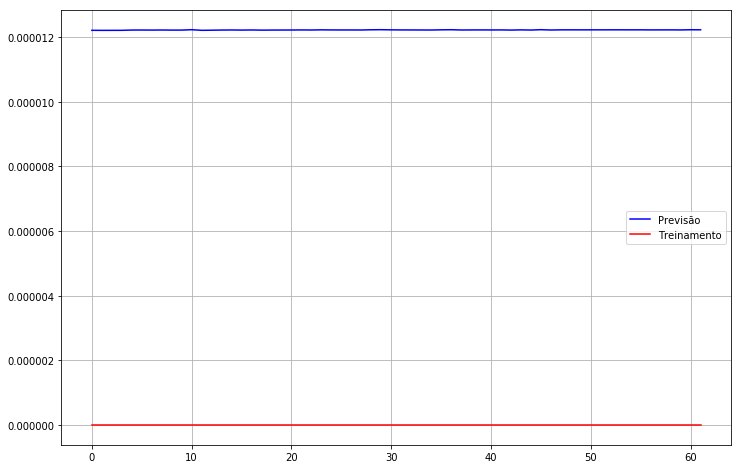

In [98]:
#CÉLULA KE-LIB-14
#Este trecho de código realiza a previsão dos valores de teste e plota o gráfico correspondente
y_pred_list = []
for i in range(len(X_test)) :
    X_data = X_test[i].reshape(1,time_steps,num_features)
    y_pred = model.predict(X_data)
    y_pred_list.append(y_pred)
    
y_p = np.array(y_pred_list).ravel() #este comando faz o 'flatten' do array para que possa ser colocado no gráfico
y_t = np.array(y_test).ravel()

plt.figure(figsize=(12,8))
plt.plot(y_p, 'b')
plt.plot(y_t, 'r')
plt.gca().legend(('Previsão', 'Treinamento'))
plt.grid()
plt.show()

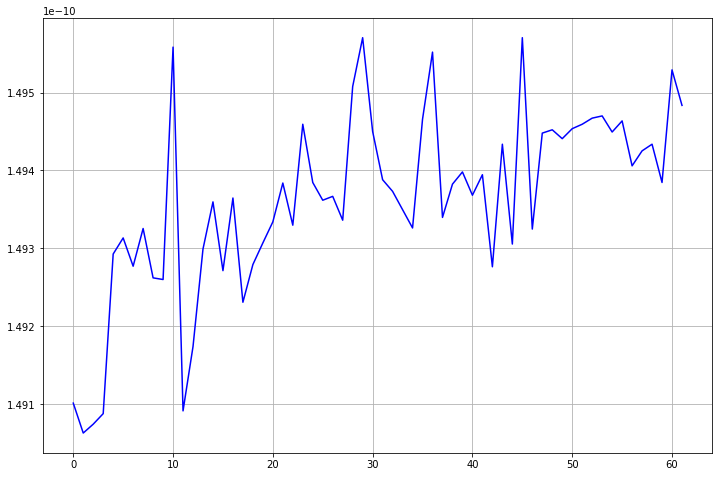

In [99]:
#CÉLULA KE-LIB-15
#IMPLEMENTE O CÓDIGO AQUI
eqm_list = []
for i in range(len(X_test)) :
    X_data = X_test[i].reshape(1,time_steps,num_features)
    y_data = y_test[i]#.reshape(1,1)
    y_pred = model.predict(X_data)
    eqm_list.append(np.mean((y_pred - y_data) ** 2))
    
eqm = np.array(eqm_list).ravel()
plt.figure(figsize=(12,8))
plt.plot(eqm, 'b')
plt.grid()
plt.show()

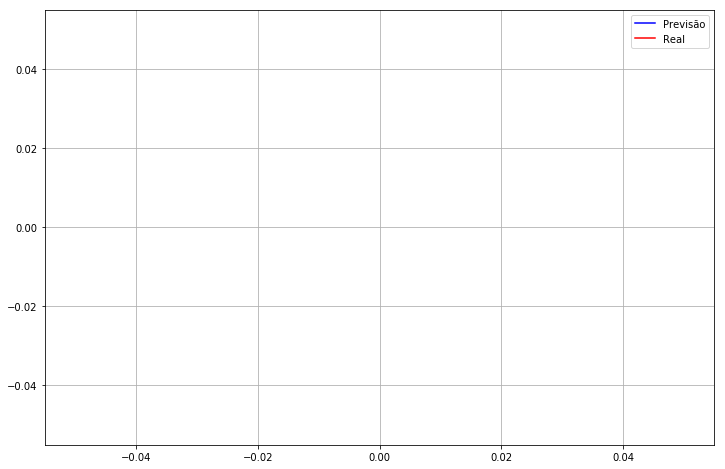

In [100]:
#CÉLULA KE-LIB-16
# Este trecho de código realiza o teste com o conjunto de validação 
y_pred_list = []
for i in range(len(y_val)) :
    y_data = y_val[i].reshape(1,time_steps,num_features)
    y_pred = model.predict(y_data)
    y_pred_list.append(y_pred)

y_p = np.array(y_pred_list).ravel()
y_t = np.array(y_test_val).ravel()
plt.figure(figsize=(12,8))
plt.plot(y_p, 'b')
plt.plot(y_t, 'r')
plt.gca().legend(('Previsão', 'Real'))
plt.grid()
plt.show()

In [101]:
b = loadDataFile('FotoMet_P1_DataSets_10T.csv', True)

In [102]:
b.head()

,painel,energia,deficit_vapor_vmedio,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio
data,,,,,,,,
2018-07-01 00:00:00,1.0,0.0,0.33,11.7,0.0,0.0,15.18,80.27
2018-07-01 00:10:00,1.0,0.0,0.31,12.0,0.0,0.0,15.21,81.63
2018-07-01 00:20:00,1.0,0.0,0.32,12.0,0.0,0.0,15.18,81.43
2018-07-01 00:30:00,1.0,0.0,0.31,11.9,0.0,0.0,15.05,81.70
2018-07-01 00:40:00,1.0,0.0,0.29,11.9,0.0,0.0,14.90,82.62


https://www.kaggle.com/amirrezaeian/time-series-data-analysis-using-lstm-tutorial

https://machinelearningmastery.com/multivariate-time-series-forecasting-lstms-keras/

In [104]:
from math import sqrt
from numpy import concatenate
from matplotlib import pyplot
from pandas import read_csv
from pandas import DataFrame
from pandas import concat
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from keras.layers import TimeDistributed
import keras as K

# convert series to supervised learning
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
    n_vars = 1 if type(data) is list else data.shape[1]
    df = pd.DataFrame(data)
    cols, names = list(), list()
    # input sequence (t-n, ... t-1)
    for i in range(n_in, 0, -1):
        cols.append(df.shift(i))
        names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
    # forecast sequence (t, t+1, ... t+n)
    for i in range(0, n_out):
        cols.append(df.shift(-i))
        if i == 0:
            names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
        else:
            names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
    # put it all together
    agg = pd.concat(cols, axis=1)
    agg.columns = names
    # drop rows with NaN values
    if dropnan:
        agg.dropna(inplace=True)
    return agg
 
# load dataset
dataset = loadDataFile('FotoMet_P1_DataSets_10T.csv', True)
dataset = dataset[['energia','temperatura_ar_vmedio','umidade_ar_vmedio']]
#dataset = read_csv('../Beiijing/pollution.csv', header=0, index_col=0)
#dataset.drop(['wnd_dir'], axis=1, inplace=True)
#dataset.drop(['painel'], axis=1, inplace=True)

values = dataset.values
# ensure all data is float
values = values.astype('float32')

# normalize features
scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(values)
# frame as supervised learning
reframed = series_to_supervised(scaled, 1, 1)
# drop columns we don't want to predict
#reframed.drop(reframed.columns[[9,10,11,12,13,14,15]], axis=1, inplace=True)
reframed.drop(reframed.columns[[4,5]], axis=1, inplace=True)
print(reframed.head())

   var1(t-1)  var2(t-1)  var3(t-1)  var1(t)
1        0.0   0.298100   0.796529      0.0
2        0.0   0.298990   0.813269      0.0
3        0.0   0.298100   0.810807      0.0
4        0.0   0.294240   0.814131      0.0
5        0.0   0.289786   0.825455      0.0


In [105]:
# split into train and test sets
values = reframed.values
n_train_hours = int(len(values) * 0.85)
train = values[:n_train_hours, :]
test = values[n_train_hours:, :]

# split into input and outputs
train_X, train_y = train[:, :-1], train[:, -1]
test_X, test_y = test[:, :-1], test[:, -1]

# reshape input to be 3D [samples, timesteps, features]
train_X = train_X.reshape((train_X.shape[0], 1, train_X.shape[1]))
test_X = test_X.reshape((test_X.shape[0], 1, test_X.shape[1]))
# We reshaped the input into the 3D format as expected by LSTMs, namely [samples, timesteps, features].
print(train_X.shape, train_y.shape, test_X.shape, test_y.shape)

(37698, 1, 3) (37698,) (6653, 1, 3) (6653,)


In [106]:
# design network
model = Sequential()
model.add(LSTM(50, input_shape=(train_X.shape[1], train_X.shape[2])))
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae', 'mse'])
model.summary()
# fit network
history = model.fit(train_X, train_y, epochs=50, batch_size=72, validation_data=(test_X, test_y), verbose=2, shuffle=False)

_________________________________________________________________
Layer (type)                 Output Shape              Param #   
lstm_2 (LSTM)                (None, 50)                10800     
_________________________________________________________________
dense_2 (Dense)              (None, 1)                 51        
Total params: 10,851
Trainable params: 10,851
Non-trainable params: 0
_________________________________________________________________
Train on 37698 samples, validate on 6653 samples
Epoch 1/50
 - 6s - loss: 0.0011 - mean_absolute_error: 0.0211 - mean_squared_error: 0.0011 - val_loss: 3.1623e-04 - val_mean_absolute_error: 0.0093 - val_mean_squared_error: 3.1623e-04
Epoch 2/50
 - 5s - loss: 5.1547e-04 - mean_absolute_error: 0.0100 - mean_squared_error: 5.1547e-04 - val_loss: 3.1210e-04 - val_mean_absolute_error: 0.0082 - val_mean_squared_error: 3.1210e-04
Epoch 3/50
 - 5s - loss: 5.1264e-04 - mean_absolute_error: 0.0100 - mean_squared_error: 5.1264e-04 - val_lo

In [115]:

#Limpa o modelo previamente usado, senão irá acumular camadas
K.backend.clear_session()

tf.logging.set_verbosity(tf.logging.ERROR) #desliga os warnings do tensorflow

init   = K.initializers.glorot_uniform(seed=1)

# design network
model = Sequential()
model.add(LSTM(units=50, return_sequences=False, input_shape=(train_X.shape[1], train_X.shape[2]),kernel_initializer=init, activation='relu'))
model.add(Dropout(0.2))
# Second LSTM layer
#model.add(LSTM(units=50))
#model.add(Dropout(0.2))
# The output layer
model.add(Dense(units=1,kernel_initializer=init, activation='relu'))
#model.compile(loss='mae', optimizer='adam')
model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae', 'mse'])


#model.add(K.layers.LSTM(units=15, return_sequences=RS_VALUE, batch_input_shape=(batch_size, time_steps, prediction), kernel_initializer=init, dropout=0.2, activation='relu')) 
#model.add(K.layers.Dense(units=1, kernel_initializer=init, activation='tanh')) #DADOS NORMALIZADOS

#model.compile(loss='mean_squared_error', optimizer=theOptimizer, metrics=['mae', 'mse'])


# fit network
history = model.fit(train_X, train_y, epochs=50, batch_size=70, validation_data=(test_X, test_y), verbose=2, shuffle=False)

ValueError: Input 0 is incompatible with layer lstm_2: expected ndim=3, found ndim=2

In [108]:
model.summary()

_________________________________________________________________
Layer (type)                 Output Shape              Param #   
lstm_1 (LSTM)                (None, 50)                10800     
_________________________________________________________________
dropout_1 (Dropout)          (None, 50)                0         
_________________________________________________________________
dense_1 (Dense)              (None, 1)                 51        
Total params: 10,851
Trainable params: 10,851
Non-trainable params: 0
_________________________________________________________________


In [109]:
eval = model.evaluate(test_X,test_y,verbose=0)
print("Dados de teste: loss = %0.6f MAE = %0.2f%% \n" \
% (eval[0], eval[1]*100) )

Dados de teste: loss = 0.003915 MAE = 3.13% 



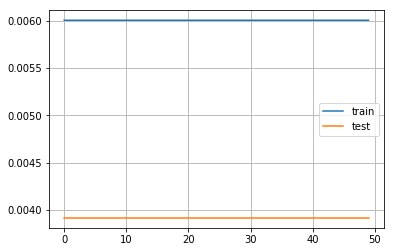

In [110]:
# plot history
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.grid()
plt.show()

In [112]:
# make a prediction
yhat = model.predict(test_X)
test_X_r = test_X.reshape((test_X.shape[0], test_X.shape[2]))
# invert scaling for forecast
inv_yhat = np.concatenate((yhat, test_X_r[:, 1:]), axis=1)#-6
inv_yhat = scaler.inverse_transform(inv_yhat)
inv_yhat = inv_yhat[:,0]
# invert scaling for actual
test_y = test_y.reshape((len(test_y), 1))
inv_y = np.concatenate((test_y, test_X_r[:, 1:]), axis=1)#-6
inv_y = scaler.inverse_transform(inv_y)
inv_y = inv_y[:,0]

In [113]:
# calculate RMSE
print('MSE: {:.10f}'.format(metrics.mean_squared_error(inv_y, inv_yhat)))
print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(inv_y, inv_yhat))))
print('r²: {:.2f} %'.format(r2_score(inv_y, inv_yhat) * 100))
print('MAE: {:.6f}'.format(mean_absolute_error(inv_y, inv_yhat)))

MSE: 338369.1250000000
RMSE: 581.695068
r²: -33.29 %
MAE: 290.695770


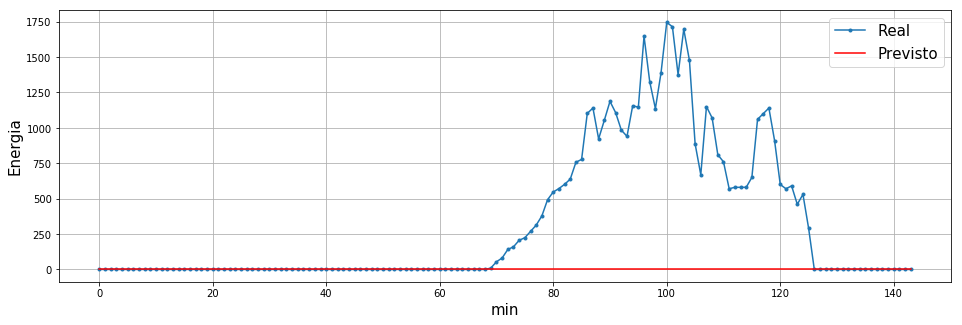

In [114]:
## time steps, every step is one hour (you can easily convert the time step to the actual time index)
## for a demonstration purpose, I only compare the predictions in 200 hours. 
#c = len(inv_y)#ou 144
c = 144
aa=[x for x in range(c)]
plt.figure(figsize=(16,5))
plt.plot(aa, inv_y[:c], marker='.', label="Real")
plt.plot(aa, inv_yhat[:c], 'r', label="Previsto")
plt.ylabel('Energia', size=15)
plt.xlabel('min', size=15)
plt.legend(fontsize=15)
plt.grid()
plt.show()

Multivariável

In [116]:
from math import sqrt
from numpy import concatenate
from matplotlib import pyplot
from pandas import read_csv
from pandas import DataFrame
from pandas import concat
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM

# convert series to supervised learning
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
    n_vars = 1 if type(data) is list else data.shape[1]
    df = pd.DataFrame(data)
    cols, names = list(), list()
    # input sequence (t-n, ... t-1)
    for i in range(n_in, 0, -1):
        cols.append(df.shift(i))
        names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
    # forecast sequence (t, t+1, ... t+n)
    for i in range(0, n_out):
        cols.append(df.shift(-i))
        if i == 0:
            names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
        else:
            names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
    # put it all together
    agg = pd.concat(cols, axis=1)
    agg.columns = names
    # drop rows with NaN values
    if dropnan:
        agg.dropna(inplace=True)
    return agg
 
# load dataset
dataset = loadDataFile('FotoMet_P1_DataSets_10T.csv', True)
dataset = dataset[['energia','radiacao_solar_valor']]
#dataset.drop(['painel'], axis=1, inplace=True)
values = dataset.values

# ensure all data is float
values = values.astype('float32')
# normalize features
scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(values)

# specify the number of lag hours
n_hours = 24 * 6
n_features = 2

# frame as supervised learning
reframed = series_to_supervised(scaled, n_hours, 1)
print(reframed.shape)

(44208, 290)


In [117]:
print(reframed.head())

     var1(t-144)  var2(t-144)  var1(t-143)  var2(t-143)  var1(t-142)  \
144          0.0          0.0          0.0          0.0          0.0   
145          0.0          0.0          0.0          0.0          0.0   
146          0.0          0.0          0.0          0.0          0.0   
147          0.0          0.0          0.0          0.0          0.0   
148          0.0          0.0          0.0          0.0          0.0   

     var2(t-142)  var1(t-141)  var2(t-141)  var1(t-140)  var2(t-140)   ...     \
144          0.0          0.0          0.0          0.0          0.0   ...      
145          0.0          0.0          0.0          0.0          0.0   ...      
146          0.0          0.0          0.0          0.0          0.0   ...      
147          0.0          0.0          0.0          0.0          0.0   ...      
148          0.0          0.0          0.0          0.0          0.0   ...      

     var1(t-4)  var2(t-4)  var1(t-3)  var2(t-3)  var1(t-2)  var2(t-2)  \
144    

In [118]:
# split into train and test sets
values = reframed.values
n_train_hours = int(len(values) * 0.85) #quantos dados irei usar para treinar o modelo
train = values[:n_train_hours, :]
test = values[n_train_hours:, :]

# split into input and outputs
n_obs = n_hours * n_features
train_X, train_y = train[:, :n_obs], train[:, -n_features]
test_X, test_y = test[:, :n_obs], test[:, -n_features]
print(train_X.shape, len(train_X), train_y.shape)

# reshape input to be 3D [samples, timesteps, features]
train_X = train_X.reshape((train_X.shape[0], n_hours, n_features))
test_X = test_X.reshape((test_X.shape[0], n_hours, n_features))
print(train_X.shape, train_y.shape, test_X.shape, test_y.shape)

(37576, 288) 37576 (37576,)
(37576, 144, 2) (37576,) (6632, 144, 2) (6632,)


In [119]:
# design network
model = Sequential()
model.add(LSTM(units=50, return_sequences=False, input_shape=(train_X.shape[1], train_X.shape[2])))
model.add(Dropout(0.2))
# Second LSTM layer
#model.add(LSTM(units=50))
#model.add(Dropout(0.2))
# The output layer
model.add(Dense(units=1))
model.compile(loss='mae', optimizer='adam')

# fit network
history = model.fit(train_X, train_y, epochs=20, batch_size=72, validation_data=(test_X, test_y), verbose=2, shuffle=False)

Train on 37576 samples, validate on 6632 samples
Epoch 1/20
 - 200s - loss: 0.0130 - val_loss: 0.0085
Epoch 2/20
 - 225s - loss: 0.0102 - val_loss: 0.0075
Epoch 3/20
 - 192s - loss: 0.0096 - val_loss: 0.0075
Epoch 4/20
 - 203s - loss: 0.0093 - val_loss: 0.0071
Epoch 5/20
 - 210s - loss: 0.0092 - val_loss: 0.0068
Epoch 6/20
 - 204s - loss: 0.0091 - val_loss: 0.0069
Epoch 7/20
 - 182s - loss: 0.0091 - val_loss: 0.0069
Epoch 8/20
 - 187s - loss: 0.0090 - val_loss: 0.0070
Epoch 9/20
 - 199s - loss: 0.0090 - val_loss: 0.0069
Epoch 10/20
 - 192s - loss: 0.0090 - val_loss: 0.0067
Epoch 11/20
 - 183s - loss: 0.0089 - val_loss: 0.0068
Epoch 12/20
 - 186s - loss: 0.0089 - val_loss: 0.0067
Epoch 13/20
 - 184s - loss: 0.0088 - val_loss: 0.0069
Epoch 14/20
 - 186s - loss: 0.0089 - val_loss: 0.0070
Epoch 15/20
 - 190s - loss: 0.0088 - val_loss: 0.0067
Epoch 16/20
 - 196s - loss: 0.0088 - val_loss: 0.0066
Epoch 17/20
 - 195s - loss: 0.0087 - val_loss: 0.0067
Epoch 18/20
 - 188s - loss: 0.0087 - val_l

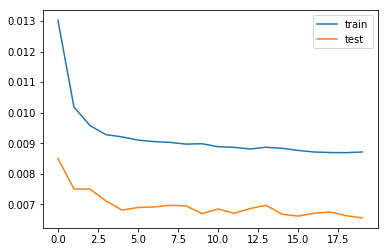

In [120]:
# plot history
pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='test')
pyplot.legend()
pyplot.show()

In [121]:
# make a prediction
y_pred_Test = model.predict(test_X)
test_X = test_X.reshape((test_X.shape[0], n_hours*n_features))

y_pred_Train = model.predict(train_X)
train_X = train_X.reshape((train_X.shape[0], n_hours*n_features))

# invert scaling for forecast
inv_y_pred_Test = concatenate((y_pred_Test, test_X[:, -(n_features-1):]), axis=1)
inv_y_pred_Test = scaler.inverse_transform(inv_y_pred_Test)
inv_y_pred_Test = inv_y_pred_Test[:,0]

inv_y_pred_Train = concatenate((y_pred_Train, train_X[:, -(n_features-1):]), axis=1)
inv_y_pred_Train = scaler.inverse_transform(inv_y_pred_Train)
inv_y_pred_Train = inv_y_pred_Train[:,0]

# invert scaling for actual
test_y = test_y.reshape((len(test_y), 1))
inv_y_Test = concatenate((test_y, test_X[:, -(n_features-1):]), axis=1)
inv_y_Test = scaler.inverse_transform(inv_y_Test)
inv_y_Test = inv_y_Test[:,0]

train_y = train_y.reshape((len(train_y), 1))
inv_y_Train = concatenate((train_y, train_X[:, -(n_features-1):]), axis=1)
inv_y_Train = scaler.inverse_transform(inv_y_Train)
inv_y_Train = inv_y_Train[:,0]

In [123]:
print('------------------- TREINO -------------------------')
print('MSE: {:.6f}'.format(metrics.mean_squared_error(inv_y_Train, inv_y_pred_Train)))
print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(inv_y_Train, inv_y_pred_Train))))
print('r²: {:.2f} %'.format(r2_score(inv_y_Train, inv_y_pred_Train) * 100))
print('MAE: {:.6f}'.format(mean_absolute_error(inv_y_Train, inv_y_pred_Train)))
print('------------------- TESTE ---------------------------')
print('MSE: {:.6f}'.format(metrics.mean_squared_error(inv_y_Test, inv_y_pred_Test)))
print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(inv_y_Test, inv_y_pred_Test))))
print('r²: {:.2f} %'.format(r2_score(inv_y_Test, inv_y_pred_Test) * 100))
print('MAE: {:.6f}'.format(mean_absolute_error(inv_y_Test, inv_y_pred_Test)))

------------------- TREINO -------------------------
MSE: 38482.316406
RMSE: 196.169098
r²: 89.98 %
MAE: 73.175461
------------------- TESTE ---------------------------
MSE: 25567.822266
RMSE: 159.899414
r²: 89.95 %
MAE: 60.911434


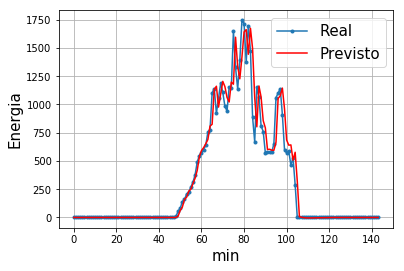

In [122]:
aa=[x for x in range(144)]
plt.plot(aa, inv_y_Test[:144], marker='.', label="Real")
plt.plot(aa, inv_y_pred_Test[:144], 'r', label="Previsto")
plt.ylabel('Energia', size=15)
plt.xlabel('min', size=15)
plt.legend(fontsize=15)
plt.grid()
plt.show()

https://www.kaggle.com/anil777/intro-to-recurrent-neural-networks-lstm-gru/data

https://machinelearningmastery.com/multivariate-time-series-forecasting-lstms-keras/

https://www.kaggle.com/humamfauzi/multiple-stock-prediction-using-single-nn

https://medium.com/alexandre-george-lustosa/previs%C3%A3o-de-pre%C3%A7o-petr4-com-python-lstm-f93722be59e0

https://towardsdatascience.com/predicting-stock-price-with-lstm-13af86a74944

https://www.kaggle.com/thebrownviking20/intro-to-recurrent-neural-networks-lstm-gru

In [40]:
dataset = loadDataFile('input/FotoMet_P1_DataSets_10T.csv', True)
dataset.drop(['painel'], axis=1, inplace=True)

In [41]:
training_set = dataset[:'2019-05-31'].iloc[:,1:2].values
test_set = dataset['2019-06-01':].iloc[:,1:2].values

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:2: FutureWarning: using a dict on a Series for aggregation
is deprecated and will be removed in a future version
  


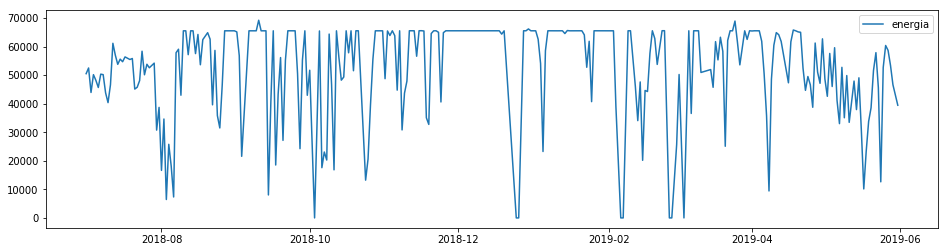

In [42]:
a = dataset["energia"][:'2019-05-31']
b = a.groupby(by=a.index.date).agg({"energia":'sum'})
b.plot(figsize=(16,4),legend=True)
plt.show()

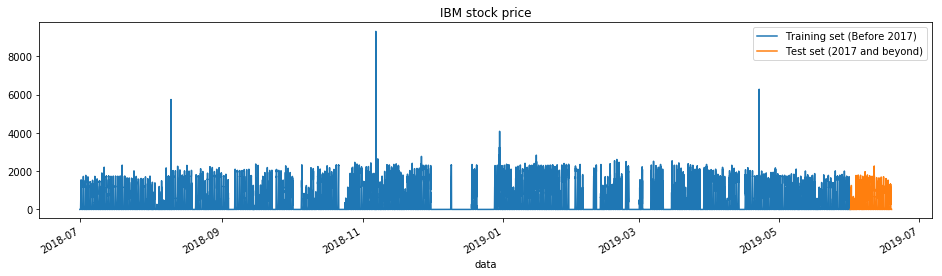

In [43]:
dataset["energia"][:'2019-05-31'].plot(figsize=(16,4),legend=True)
dataset["energia"]['2019-06-01':].plot(figsize=(16,4),legend=True)
plt.legend(['Training set (Before 2017)','Test set (2017 and beyond)'])
plt.title('IBM stock price')
plt.show()

In [44]:
sc = MinMaxScaler(feature_range=(0,1))
training_set_scaled = sc.fit_transform(training_set)

In [46]:
# Since LSTMs store long term memory state, we create a data structure with 60 timesteps and 1 output
# So for each element of training set, we have 60 previous training set elements 

minuts = 6 * 24 #(10 em 10 = 6 medicoes em 1 hora * 24 = 1 dia)
X_train = []
y_train = []
for i in range(minuts,len(training_set_scaled)):
    X_train.append(training_set_scaled[i-minuts:i,0])
    y_train.append(training_set_scaled[i,0])
X_train, y_train = np.array(X_train), np.array(y_train)

In [47]:
X_train

array([[0.0537037 , 0.05      , 0.05185185, ..., 0.06851852, 0.06296296,
        0.05555556],
       [0.05      , 0.05185185, 0.05      , ..., 0.06296296, 0.05555556,
        0.0537037 ],
       [0.05185185, 0.05      , 0.0462963 , ..., 0.05555556, 0.0537037 ,
        0.05      ],
       ...,
       [0.06851852, 0.06481481, 0.06481481, ..., 0.01666667, 0.01481481,
        0.01481481],
       [0.06481481, 0.06481481, 0.05925926, ..., 0.01481481, 0.01481481,
        0.01481481],
       [0.06481481, 0.05925926, 0.06111111, ..., 0.01481481, 0.01481481,
        0.01296296]])

In [48]:
# Reshaping X_train for efficient modelling
X_train = np.reshape(X_train, (X_train.shape[0],X_train.shape[1],1))

In [49]:
from keras.layers import Dense, LSTM, Dropout, GRU, Bidirectional

In [62]:
# The LSTM architecture
regressor = Sequential()
# First LSTM layer with Dropout regularisation
regressor.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1],1)))
regressor.add(Dropout(0.2))
# Second LSTM layer
regressor.add(LSTM(units=50))
regressor.add(Dropout(0.2))
# The output layer
regressor.add(Dense(units=1))

# Compiling the RNN
regressor.compile(optimizer='rmsprop',loss='mean_squared_error')
# Fitting to the training set
regressor.fit(X_train,y_train,epochs=3,batch_size=32)#50

ValueError: Error when checking target: expected dense_6 to have 3 dimensions, but got array with shape (41616, 1)

In [52]:
# Now to get the test set ready in a similar way as the training set.
# The following has been done so forst 60 entires of test set have 60 previous values which is impossible to get unless we take the whole 
# 'High' attribute data for processing
dataset_total = pd.concat((dataset["energia"][:'2019-05-31'],dataset["energia"]['2019-06-01':]),axis=0)
inputs = dataset_total[len(dataset_total)-len(test_set) - minuts:].values
inputs = inputs.reshape(-1,1)
inputs  = sc.transform(inputs)

In [53]:
# Preparing X_test and predicting the prices
X_test = []
for i in range(minuts,len(inputs)):
    X_test.append(inputs[i-minuts:i,0])
X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0],X_test.shape[1],1))
predicted_stock_price = regressor.predict(X_test)
predicted_stock_price = sc.inverse_transform(predicted_stock_price)

In [58]:
import math

In [60]:
# Some functions to help out with
def plot_predictions(test,predicted):
    plt.plot(test, color='red',label='Real IBM Stock Price')
    plt.plot(predicted, color='blue',label='Predicted IBM Stock Price')
    plt.title('IBM Stock Price Prediction')
    plt.xlabel('Time')
    plt.ylabel('IBM Stock Price')
    plt.legend()
    plt.show()

def return_rmse(test,predicted):
    rmse = math.sqrt(mean_squared_error(test, predicted))
    print("The root mean squared error is {}".format(rmse))

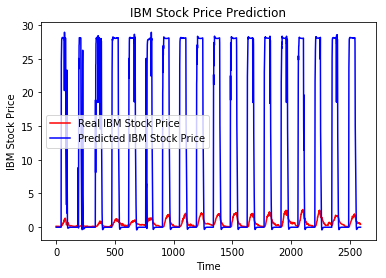

In [56]:
# Visualizing the results for LSTM
plot_predictions(test_set,predicted_stock_price)

In [61]:
# Evaluating our model
return_rmse(test_set,predicted_stock_price)

The root mean squared error is 15.688125196230242


Grafico

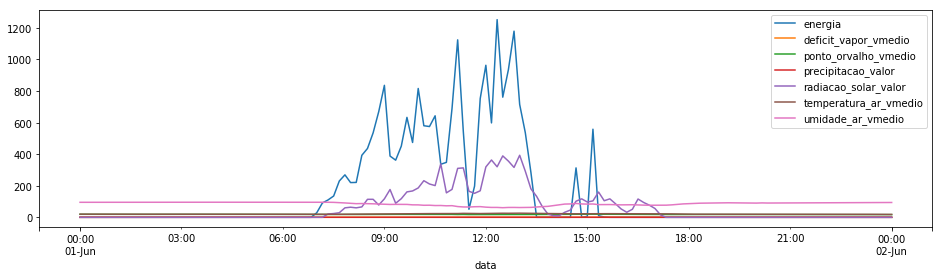

In [69]:
# weekly_summary.truncate(before='2015-01-05', after='2015-12-27')

dataset.truncate(before='2019-06-01', after='2019-06-02').plot(figsize=(16,4),legend=True)
#plt.legend(['Training set (Before 2017)','Test set (2017 and beyond)'])
#plt.title('IBM stock price')
plt.show()

In [ ]:
from pandas import read_csv
from matplotlib import pyplot
# load dataset
dataset = read_csv('pollution.csv', header=0, index_col=0)
values = dataset.values
# specify columns to plot
groups = [0, 1, 2, 3, 5, 6, 7]
i = 1
# plot each column
pyplot.figure()
for group in groups:
	pyplot.subplot(len(groups), 1, i)
	pyplot.plot(values[:, group])
	pyplot.title(dataset.columns[group], y=0.5, loc='right')
	i += 1
pyplot.show()



https://medium.com/datadriveninvestor/multivariate-time-series-using-rnn-with-keras-7f78f4488679

https://medium.com/alexandre-george-lustosa/previs%C3%A3o-de-pre%C3%A7o-petr4-com-python-lstm-f93722be59e0

https://towardsdatascience.com/time-series-analysis-visualization-forecasting-with-lstm-77a905180eba

https://www.kaggle.com/pablocastilla/predict-stock-prices-with-lstm

In [135]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

from subprocess import check_output
from keras.layers.core import Dense, Activation, Dropout
from keras.layers.recurrent import LSTM
from keras.models import Sequential
from sklearn.cross_validation import  train_test_split
import time #helper libraries
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from numpy import newaxis

C:\ProgramData\Anaconda3\lib\site-packages\sklearn\cross_validation.py:41: DeprecationWarning: This module was deprecated in version 0.18 in favor of the model_selection module into which all the refactored classes and functions are moved. Also note that the interface of the new CV iterators are different from that of this module. This module will be removed in 0.20.
  "This module will be removed in 0.20.", DeprecationWarning)


In [120]:
df = loadDataFile('input/FotoMet_P1_DataSets_10T.csv', True)
df.drop(['painel'], axis=1, inplace=True)

In [121]:
df.shape

(44352, 7)

In [122]:
energValues = df.energia.values.astype('float32')
energValues = energValues.reshape(len(energValues), 1)
energValues.shape

(44352, 1)

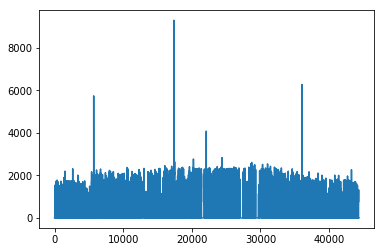

In [123]:
plt.plot(energValues)
plt.show()

In [124]:
scaler = MinMaxScaler(feature_range=(0, 1))
energScaler = scaler.fit_transform(energValues)

In [125]:
train_size = int(len(energScaler) * 0.80)
test_size = len(energScaler) - train_size
train, test = energScaler[0:train_size,:], energScaler[train_size:len(energScaler),:]
print(len(train), len(test))

35481 8871


In [126]:
# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1):
    dataX, dataY = [], []
    for i in range(len(dataset)-look_back-1):
        a = dataset[i:(i+look_back), 0]
        dataX.append(a)
        dataY.append(dataset[i + look_back, 0])
    return np.array(dataX), np.array(dataY)

In [127]:
# reshape into X=t and Y=t+1
look_back = 1
trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

In [128]:
trainX = np.reshape(trainX, (trainX.shape[0], 1, trainX.shape[1]))
testX = np.reshape(testX, (testX.shape[0], 1, testX.shape[1]))

In [132]:
#Step 2 Build Model
model = Sequential()

model.add(LSTM(
    input_dim=1,
    output_dim=50,
    return_sequences=True))
model.add(Dropout(0.2))

model.add(LSTM(
    100,
    return_sequences=False))
model.add(Dropout(0.2))

model.add(Dense(
    output_dim=1))
model.add(Activation('linear'))

model.compile(loss='mse', optimizer='rmsprop')

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:7: UserWarning: The `input_dim` and `input_length` arguments in recurrent layers are deprecated. Use `input_shape` instead.
  import sys
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:7: UserWarning: Update your `LSTM` call to the Keras 2 API: `LSTM(return_sequences=True, input_shape=(None, 1), units=50)`
  import sys
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:16: UserWarning: Update your `Dense` call to the Keras 2 API: `Dense(units=1)`
  app.launch_new_instance()


In [133]:
model.fit(
    trainX,
    trainY,
    batch_size=128,
    nb_epoch=10,
    validation_split=0.05)

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:6: UserWarning: The `nb_epoch` argument in `fit` has been renamed `epochs`.
  


Train on 33705 samples, validate on 1774 samples
Epoch 1/10
33705/33705 [==============================] - 8s 246us/step - loss: 0.0011 - val_loss: 5.4987e-04
Epoch 2/10
33705/33705 [==============================] - 3s 91us/step - loss: 5.6350e-04 - val_loss: 5.2023e-04
Epoch 3/10
33705/33705 [==============================] - 4s 114us/step - loss: 5.5424e-04 - val_loss: 5.5713e-04
Epoch 4/10
33705/33705 [==============================] - 4s 108us/step - loss: 5.5006e-04 - val_loss: 5.2377e-04
Epoch 5/10
33705/33705 [==============================] - 4s 110us/step - loss: 5.4400e-04 - val_loss: 5.9047e-04
Epoch 6/10
33705/33705 [==============================] - 3s 93us/step - loss: 5.3748e-04 - val_loss: 5.3738e-04
Epoch 7/10
33705/33705 [==============================] - 3s 90us/step - loss: 5.3585e-04 - val_loss: 5.2935e-04
Epoch 8/10
33705/33705 [==============================] - 3s 86us/step - loss: 5.3253e-04 - val_loss: 4.9614e-04
Epoch 9/10
33705/33705 [=======================

[[0.15377219]]
[[0.32793772]]
[[0.62809694]]
[[1.0470532]]
[[1.4454887]]
[[ 1429.62 ]
 [ 3048.837]
 [ 5839.417]
 [ 9734.454]
 [13438.708]]


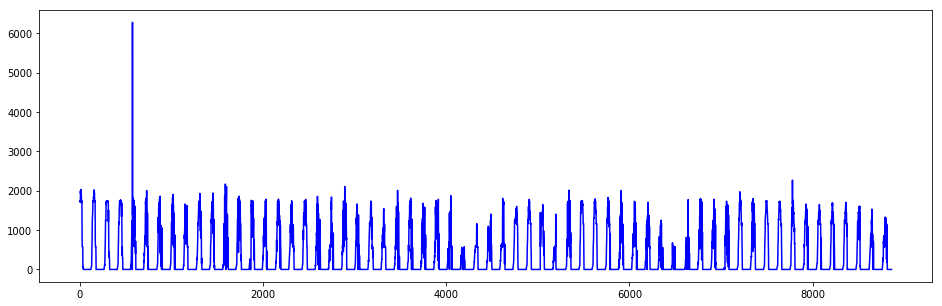

In [142]:
def plot_results_multiple(predicted_data, true_data,length):
    plt.figure(figsize=(16,5))
    plt.plot(scaler.inverse_transform(true_data.reshape(-1, 1))[length:], color='blue',label='Real')
    plt.plot(scaler.inverse_transform(np.array(predicted_data).reshape(-1, 1))[length:], color='red',label='Previsto')
    plt.show()
    
#predict lenght consecutive values from a real one
def predict_sequences_multiple(model, firstValue,length):
    prediction_seqs = []
    curr_frame = firstValue
    
    for i in range(length): 
        predicted = []        
        
        print(model.predict(curr_frame[newaxis,:,:]))
        predicted.append(model.predict(curr_frame[newaxis,:,:])[0,0])
        
        curr_frame = curr_frame[0:]
        curr_frame = np.insert(curr_frame[0:], i+1, predicted[-1], axis=0)
        
        prediction_seqs.append(predicted[-1])
        
    return prediction_seqs

predict_length=5
predictions = predict_sequences_multiple(model, testX[0], predict_length)
print(scaler.inverse_transform(np.array(predictions).reshape(-1, 1)))
plot_results_multiple(predictions, testY, predict_length)

In [145]:
testY.shape

(8869,)

https://machinelearningmastery.com/how-to-develop-lstm-models-for-multi-step-time-series-forecasting-of-household-power-consumption/

https://machinelearningmastery.com/time-series-prediction-lstm-recurrent-neural-networks-python-keras/